# Experimental data analysis: Bräcklein et al. (2022)

This notebook analyzes experimental data from motor learning experiments where subjects learned to independently control two motoneurons.

**Experimental design:**
- 6 subjects 
- Multiple training days (Day01-Day14, varying by subject)
- Multiple trials per day 
- Each trial contains: spike trains (MU), force signal, MU pair indices,...

---

## 1. Environment setup

### 1.1 Package imports

In [20]:
# Core packages
import os
import re
import sys
import math
import pickle
from collections import defaultdict

# Data handling
import numpy as np
import pandas as pd
import h5py

# Statistical analysis
from scipy import signal, stats
from scipy.stats import (zscore, ks_2samp, linregress, pearsonr, mannwhitneyu)
from scipy.signal import (convolve, windows, resample)
from scipy.ndimage import gaussian_filter1d
from scipy.interpolate import interp1d
from scipy.sparse import csr_matrix

# Machine learning
from sklearn.preprocessing import (PolynomialFeatures, StandardScaler)
from sklearn.model_selection import (train_test_split, cross_val_score, KFold, GridSearchCV)
from sklearn.linear_model import PoissonRegressor
from sklearn.pipeline import make_pipeline
from pyglmnet import GLM

# Visualization
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib import cm
from matplotlib.colors import Normalize
from mpl_toolkits.mplot3d import Axes3D

# Add custom analysis functions to path
sys.path.insert(0, "/Users/nmt121/Desktop/Repositories/Motoneuron_Model")

print("✓ All packages loaded successfully")

✓ All packages loaded successfully


---

## 2. Data configuration

### 2.1 Define data paths and session files

Each subject has a dictionary mapping session days to trial filenames.

In [2]:
# Base directory for experimental data
base_data_dir = "/Users/nmt121/Desktop/DATA"

# Subject identifiers
subjects = ['S1', 'S2', 'S3', 'S4', 'S6', 'S7']

print("Data configuration:")
print(f"  Base directory: {base_data_dir}")
print(f"  Subjects: {', '.join(subjects)}")
print(f"  Sampling frequency (force): 2048 Hz")
print(f"  File format: .pkl (contains MU, Force, Idx_MU_Pair)")

Data configuration:
  Base directory: /Users/nmt121/Desktop/DATA
  Subjects: S1, S2, S3, S4, S6, S7
  Sampling frequency (force): 2048 Hz
  File format: .pkl (contains MU, Force, Idx_MU_Pair)


### 2.2 Subject 1 (S1) - Session files

In [13]:
session_files1 = {
    "Day01": ['E3_MB01_Day01High_1.pkl','E3_MB01_Day01High_11.pkl','E3_MB01_Day01High_14.pkl','E3_MB01_Day01High_17.pkl','E3_MB01_Day01High_21.pkl','E3_MB01_Day01High_24.pkl','E3_MB01_Day01High_27.pkl','E3_MB01_Day01High_30.pkl','E3_MB01_Day01High_6.pkl','E3_MB01_Day01High_9.pkl'],
    "Day03": ['E3_MB01_Day03High_11.pkl','E3_MB01_Day03High_14.pkl','E3_MB01_Day03High_18.pkl','E3_MB01_Day03High_21.pkl','E3_MB01_Day03High_23.pkl','E3_MB01_Day03High_26.pkl','E3_MB01_Day03High_29.pkl','E3_MB01_Day03High_3.pkl','E3_MB01_Day03High_4.pkl','E3_MB01_Day03High_9.pkl'],
    "Day04": ['E3_MB01_Day04High_1.pkl','E3_MB01_Day04High_10.pkl','E3_MB01_Day04High_13.pkl','E3_MB01_Day04High_17.pkl','E3_MB01_Day04High_20.pkl','E3_MB01_Day04High_23.pkl','E3_MB01_Day04High_25.pkl','E3_MB01_Day04High_29.pkl','E3_MB01_Day04High_30.pkl','E3_MB01_Day04High_6.pkl','E3_MB01_Day04High_9.pkl'],
    "Day05": ['E3_MB01_Day05High_1.pkl','E3_MB01_Day05High_10.pkl','E3_MB01_Day05High_13.pkl','E3_MB01_Day05High_18.pkl','E3_MB01_Day05High_21.pkl','E3_MB01_Day05High_23.pkl','E3_MB01_Day05High_26.pkl','E3_MB01_Day05High_28.pkl','E3_MB01_Day05High_5.pkl','E3_MB01_Day05High_9.pkl'],
    "Day06": ['E3_MB01_Day06High_10.pkl','E3_MB01_Day06High_14.pkl','E3_MB01_Day06High_18.pkl','E3_MB01_Day06High_21.pkl','E3_MB01_Day06High_22.pkl','E3_MB01_Day06High_26.pkl','E3_MB01_Day06High_3.pkl','E3_MB01_Day06High_30.pkl','E3_MB01_Day06High_5.pkl','E3_MB01_Day06High_9.pkl'],
    "Day07": ['E3_MB01_Day07High_1.pkl','E3_MB01_Day07High_10.pkl','E3_MB01_Day07High_14.pkl','E3_MB01_Day07High_18.pkl','E3_MB01_Day07High_19.pkl','E3_MB01_Day07High_23.pkl','E3_MB01_Day07High_26.pkl','E3_MB01_Day07High_28.pkl','E3_MB01_Day07High_5.pkl','E3_MB01_Day07High_9.pkl'],
    "Day08": ['E3_MB01_Day08High_12.pkl','E3_MB01_Day08High_13.pkl','E3_MB01_Day08High_17.pkl','E3_MB01_Day08High_21.pkl','E3_MB01_Day08High_23.pkl','E3_MB01_Day08High_25.pkl','E3_MB01_Day08High_3.pkl','E3_MB01_Day08High_30.pkl','E3_MB01_Day08High_7.pkl'],
    "Day09": ['E3_MB01_Day09High_1.pkl','E3_MB01_Day09High_13.pkl','E3_MB01_Day09High_15.pkl','E3_MB01_Day09High_18.pkl','E3_MB01_Day09High_23.pkl','E3_MB01_Day09High_26.pkl','E3_MB01_Day09High_27.pkl','E3_MB01_Day09High_4.pkl','E3_MB01_Day09High_8.pkl','E3_MB01_Day09High_9.pkl'],
    "Day10": ['E3_MB01_Day10High_1.pkl','E3_MB01_Day10High_10.pkl','E3_MB01_Day10High_15.pkl','E3_MB01_Day10High_18.pkl','E3_MB01_Day10High_19.pkl','E3_MB01_Day10High_22.pkl','E3_MB01_Day10High_25.pkl','E3_MB01_Day10High_30.pkl','E3_MB01_Day10High_5.pkl','E3_MB01_Day10High_7.pkl'],
    "Day11": ['E3_MB01_Day11High_12.pkl','E3_MB01_Day11High_15.pkl','E3_MB01_Day11High_18.pkl','E3_MB01_Day11High_20.pkl','E3_MB01_Day11High_24.pkl','E3_MB01_Day11High_25.pkl','E3_MB01_Day11High_28.pkl','E3_MB01_Day11High_3.pkl','E3_MB01_Day11High_4.pkl','E3_MB01_Day11High_8.pkl'],
    "Day12": ['E3_MB01_Day12High_12.pkl','E3_MB01_Day12High_15.pkl','E3_MB01_Day12High_17.pkl','E3_MB01_Day12High_2.pkl','E3_MB01_Day12High_20.pkl','E3_MB01_Day12High_24.pkl','E3_MB01_Day12High_25.pkl','E3_MB01_Day12High_28.pkl','E3_MB01_Day12High_4.pkl','E3_MB01_Day12High_7.pkl'],
    "Day13": ['E3_MB01_Day13High_1.pkl','E3_MB01_Day13High_12.pkl','E3_MB01_Day13High_14.pkl','E3_MB01_Day13High_16.pkl','E3_MB01_Day13High_19.pkl','E3_MB01_Day13High_23.pkl','E3_MB01_Day13High_25.pkl','E3_MB01_Day13High_30.pkl','E3_MB01_Day13High_5.pkl','E3_MB01_Day13High_9.pkl'],
    "Day14": ['E3_MB01_Day14High_12.pkl','E3_MB01_Day14High_15.pkl','E3_MB01_Day14High_18.pkl','E3_MB01_Day14High_19.pkl','E3_MB01_Day14High_22.pkl','E3_MB01_Day14High_26.pkl','E3_MB01_Day14High_28.pkl','E3_MB01_Day14High_3.pkl','E3_MB01_Day14High_5.pkl','E3_MB01_Day14High_8.pkl']
}

print(f"Subject 1 sessions: {len(session_files1)} days")
print(f"  Total trials: {sum(len(v) for v in session_files1.values())}")

Subject 1 sessions: 13 days
  Total trials: 130


### 2.3 Other subjects' session files


In [ ]:
session_files2 = {
    "Day02": ['E3_MB02_Day02High_10.pkl','E3_MB02_Day02High_14.pkl','E3_MB02_Day02High_18.pkl','E3_MB02_Day02High_2.pkl','E3_MB02_Day02High_20.pkl','E3_MB02_Day02High_24.pkl','E3_MB02_Day02High_27.pkl','E3_MB02_Day02High_29.pkl','E3_MB02_Day02High_6.pkl','E3_MB02_Day02High_9.pkl'],
    "Day03": ['E3_MB02_Day03High_11.pkl','E3_MB02_Day03High_13.pkl','E3_MB02_Day03High_18.pkl','E3_MB02_Day03High_21.pkl','E3_MB02_Day03High_24.pkl','E3_MB02_Day03High_26.pkl','E3_MB02_Day03High_29.pkl','E3_MB02_Day03High_3.pkl','E3_MB02_Day03High_5.pkl','E3_MB02_Day03High_7.pkl'],
    "Day04": ['E3_MB02_Day04High_11.pkl','E3_MB02_Day04High_14.pkl','E3_MB02_Day04High_16.pkl','E3_MB02_Day04High_2.pkl','E3_MB02_Day04High_21.pkl','E3_MB02_Day04High_22.pkl','E3_MB02_Day04High_27.pkl','E3_MB02_Day04High_30.pkl','E3_MB02_Day04High_5.pkl','E3_MB02_Day04High_7.pkl'],
    "Day07": ['E3_MB02_Day07High_1.pkl','E3_MB02_Day07High_12.pkl','E3_MB02_Day07High_13.pkl','E3_MB02_Day07High_16.pkl','E3_MB02_Day07High_19.pkl','E3_MB02_Day07High_24.pkl','E3_MB02_Day07High_27.pkl','E3_MB02_Day07High_30.pkl','E3_MB02_Day07High_4.pkl','E3_MB02_Day07High_9.pkl'],
    "Day13": ['E3_MB02_Day13High_1.pkl','E3_MB02_Day13High_11.pkl','E3_MB02_Day13High_13.pkl','E3_MB02_Day13High_18.pkl','E3_MB02_Day13High_20.pkl','E3_MB02_Day13High_23.pkl','E3_MB02_Day13High_26.pkl','E3_MB02_Day13High_28.pkl','E3_MB02_Day13High_4.pkl','E3_MB02_Day13High_8.pkl']
}


session_files3 = {
    "Day01": ['E3_MB03_Day01High_12.pkl','E3_MB03_Day01High_14.pkl','E3_MB03_Day01High_16.pkl','E3_MB03_Day01High_19.pkl','E3_MB03_Day01High_23.pkl','E3_MB03_Day01High_27.pkl','E3_MB03_Day01High_29.pkl','E3_MB03_Day01High_3.pkl','E3_MB03_Day01High_4.pkl','E3_MB03_Day01High_8.pkl'],
    "Day02": ['E3_MB03_Day02High_12.pkl','E3_MB03_Day02High_15.pkl','E3_MB03_Day02High_17.pkl','E3_MB03_Day02High_19.pkl','E3_MB03_Day02High_2.pkl','E3_MB03_Day02High_24.pkl','E3_MB03_Day02High_26.pkl','E3_MB03_Day02High_29.pkl','E3_MB03_Day02High_6.pkl','E3_MB03_Day02High_8.pkl'],
    "Day03": ['E3_MB03_Day03High_10.pkl','E3_MB03_Day03High_15.pkl','E3_MB03_Day03High_17.pkl','E3_MB03_Day03High_2.pkl','E3_MB03_Day03High_21.pkl','E3_MB03_Day03High_23.pkl','E3_MB03_Day03High_26.pkl','E3_MB03_Day03High_29.pkl','E3_MB03_Day03High_5.pkl','E3_MB03_Day03High_9.pkl'],
    "Day04": ['E3_MB03_Day04High_1.pkl','E3_MB03_Day04High_11.pkl','E3_MB03_Day04High_15.pkl','E3_MB03_Day04High_16.pkl','E3_MB03_Day04High_20.pkl','E3_MB03_Day04High_23.pkl','E3_MB03_Day04High_26.pkl','E3_MB03_Day04High_28.pkl','E3_MB03_Day04High_4.pkl','E3_MB03_Day04High_9.pkl'],
    "Day05": ['E3_MB03_Day05High_12.pkl','E3_MB03_Day05High_15.pkl','E3_MB03_Day05High_17.pkl','E3_MB03_Day05High_20.pkl','E3_MB03_Day05High_22.pkl','E3_MB03_Day05High_26.pkl','E3_MB03_Day05High_29.pkl','E3_MB03_Day05High_3.pkl','E3_MB03_Day05High_4.pkl','E3_MB03_Day05High_7.pkl'],
    "Day07": ['E3_MB03_Day07High_11.pkl','E3_MB03_Day07High_13.pkl','E3_MB03_Day07High_18.pkl','E3_MB03_Day07High_19.pkl','E3_MB03_Day07High_22.pkl','E3_MB03_Day07High_27.pkl','E3_MB03_Day07High_29.pkl','E3_MB03_Day07High_3.pkl','E3_MB03_Day07High_7.pkl'],
    "Day10": ['E3_MB03_Day10High_12.pkl','E3_MB03_Day10High_13.pkl','E3_MB03_Day10High_17.pkl','E3_MB03_Day10High_21.pkl','E3_MB03_Day10High_22.pkl','E3_MB03_Day10High_25.pkl','E3_MB03_Day10High_3.pkl','E3_MB03_Day10High_30.pkl','E3_MB03_Day10High_5.pkl','E3_MB03_Day10High_8.pkl'],
    "Day11": ['E3_MB03_Day11High_10.pkl','E3_MB03_Day11High_14.pkl','E3_MB03_Day11High_18.pkl','E3_MB03_Day11High_20.pkl','E3_MB03_Day11High_23.pkl','E3_MB03_Day11High_26.pkl','E3_MB03_Day11High_3.pkl','E3_MB03_Day11High_30.pkl','E3_MB03_Day11High_6.pkl','E3_MB03_Day11High_9.pkl'],
    "Day12": ['E3_MB03_Day12High_12.pkl','E3_MB03_Day12High_13.pkl','E3_MB03_Day12High_17.pkl','E3_MB03_Day12High_21.pkl','E3_MB03_Day12High_22.pkl','E3_MB03_Day12High_25.pkl','E3_MB03_Day12High_29.pkl','E3_MB03_Day12High_3.pkl','E3_MB03_Day12High_5.pkl','E3_MB03_Day12High_8.pkl'],
    "Day13": ['E3_MB03_Day13High_12.pkl','E3_MB03_Day13High_13.pkl','E3_MB03_Day13High_18.pkl','E3_MB03_Day13High_19.pkl','E3_MB03_Day13High_2.pkl','E3_MB03_Day13High_24.pkl','E3_MB03_Day13High_27.pkl','E3_MB03_Day13High_29.pkl','E3_MB03_Day13High_5.pkl','E3_MB03_Day13High_7.pkl'],
    "Day14": ['E3_MB03_Day14High_12.pkl','E3_MB03_Day14High_13.pkl','E3_MB03_Day14High_16.pkl','E3_MB03_Day14High_21.pkl','E3_MB03_Day14High_24.pkl','E3_MB03_Day14High_26.pkl','E3_MB03_Day14High_29.pkl','E3_MB03_Day14High_3.pkl','E3_MB03_Day14High_4.pkl','E3_MB03_Day14High_8.pkl']
}


session_files4 = {
    "Day01": ['E3_MB04_Day01High_16.pkl','E3_MB04_Day01High_19.pkl','E3_MB04_Day01High_2.pkl','E3_MB04_Day01High_24.pkl','E3_MB04_Day01High_26.pkl','E3_MB04_Day01High_30.pkl','E3_MB04_Day01High_6.pkl','E3_MB04_Day01High_8.pkl'],
    "Day03": ['E3_MB04_Day03High_10.pkl','E3_MB04_Day03High_14.pkl','E3_MB04_Day03High_17.pkl','E3_MB04_Day03High_19.pkl','E3_MB04_Day03High_22.pkl','E3_MB04_Day03High_27.pkl','E3_MB04_Day03High_28.pkl','E3_MB04_Day03High_3.pkl','E3_MB04_Day03High_5.pkl','E3_MB04_Day03High_8.pkl'],
    "Day07": ['E3_MB04_Day07High_15.pkl','E3_MB04_Day07High_29.pkl','E3_MB04_Day07High_6.pkl','E3_MB04_Day07High_8.pkl'],
    "Day08": ['E3_MB04_Day08High_11.pkl','E3_MB04_Day08High_13.pkl','E3_MB04_Day08High_18.pkl','E3_MB04_Day08High_19.pkl','E3_MB04_Day08High_2.pkl','E3_MB04_Day08High_22.pkl','E3_MB04_Day08High_27.pkl','E3_MB04_Day08High_28.pkl','E3_MB04_Day08High_6.pkl','E3_MB04_Day08High_9.pkl'],
    "Day09": ['E3_MB04_Day09High_1.pkl','E3_MB04_Day09High_19.pkl','E3_MB04_Day09High_24.pkl','E3_MB04_Day09High_27.pkl','E3_MB04_Day09High_30.pkl','E3_MB04_Day09High_6.pkl'],
    "Day10": ['E3_MB04_Day10High_11.pkl','E3_MB04_Day10High_15.pkl','E3_MB04_Day10High_17.pkl','E3_MB04_Day10High_2.pkl','E3_MB04_Day10High_21.pkl','E3_MB04_Day10High_22.pkl','E3_MB04_Day10High_26.pkl','E3_MB04_Day10High_28.pkl','E3_MB04_Day10High_4.pkl','E3_MB04_Day10High_9.pkl'],
    "Day11": ['E3_MB04_Day11High_10.pkl','E3_MB04_Day11High_14.pkl','E3_MB04_Day11High_16.pkl','E3_MB04_Day11High_2.pkl','E3_MB04_Day11High_21.pkl','E3_MB04_Day11High_23.pkl','E3_MB04_Day11High_27.pkl','E3_MB04_Day11High_28.pkl','E3_MB04_Day11High_4.pkl','E3_MB04_Day11High_9.pkl'],
    "Day12": ['E3_MB04_Day12High_2.pkl','E3_MB04_Day12High_5.pkl','E3_MB04_Day12High_9.pkl','E3_MB04_Day12High_12.pkl','E3_MB04_Day12High_14.pkl','E3_MB04_Day12High_18.pkl','E3_MB04_Day12High_19.pkl','E3_MB04_Day12High_23.pkl','E3_MB04_Day12High_26.pkl','E3_MB04_Day12High_29.pkl'],
    "Day13": ['E3_MB04_Day13High_3.pkl','E3_MB04_Day13High_4.pkl','E3_MB04_Day13High_8.pkl','E3_MB04_Day13High_12.pkl','E3_MB04_Day13High_14.pkl','E3_MB04_Day13High_18.pkl','E3_MB04_Day13High_19.pkl','E3_MB04_Day13High_24.pkl','E3_MB04_Day13High_27.pkl','E3_MB04_Day13High_30.pkl'],
    "Day14": ['E3_MB04_Day14High_3.pkl','E3_MB04_Day14High_4.pkl','E3_MB04_Day14High_8.pkl','E3_MB04_Day14High_11.pkl','E3_MB04_Day14High_13.pkl','E3_MB04_Day14High_18.pkl','E3_MB04_Day14High_21.pkl','E3_MB04_Day14High_25.pkl','E3_MB04_Day14High_28.pkl']
}


session_files6 = {
    "Day01": ['E3_MB06_Day01High_10.pkl','E3_MB06_Day01High_13.pkl','E3_MB06_Day01High_16.pkl','E3_MB06_Day01High_2.pkl','E3_MB06_Day01High_21.pkl','E3_MB06_Day01High_22.pkl','E3_MB06_Day01High_27.pkl','E3_MB06_Day01High_28.pkl','E3_MB06_Day01High_6.pkl','E3_MB06_Day01High_7.pkl'],
    "Day03": ['E3_MB06_Day03High_1.pkl','E3_MB06_Day03High_10.pkl','E3_MB06_Day03High_14.pkl','E3_MB06_Day03High_17.pkl','E3_MB06_Day03High_21.pkl','E3_MB06_Day03High_22.pkl','E3_MB06_Day03High_27.pkl','E3_MB06_Day03High_29.pkl','E3_MB06_Day03High_6.pkl','E3_MB06_Day03High_8.pkl'],
    "Day04": ['E3_MB06_Day04High_10.pkl','E3_MB06_Day04High_14.pkl','E3_MB06_Day04High_17.pkl','E3_MB06_Day04High_21.pkl','E3_MB06_Day04High_24.pkl','E3_MB06_Day04High_26.pkl','E3_MB06_Day04High_3.pkl','E3_MB06_Day04High_30.pkl','E3_MB06_Day04High_5.pkl','E3_MB06_Day04High_9.pkl'],
    "Day05": ['E3_MB06_Day05High_1.pkl','E3_MB06_Day05High_12.pkl','E3_MB06_Day05High_13.pkl','E3_MB06_Day05High_18.pkl','E3_MB06_Day05High_20.pkl','E3_MB06_Day05High_24.pkl','E3_MB06_Day05High_27.pkl','E3_MB06_Day05High_29.pkl','E3_MB06_Day05High_5.pkl','E3_MB06_Day05High_8.pkl'],
    "Day06": ['E3_MB06_Day06High_1.pkl','E3_MB06_Day06High_12.pkl','E3_MB06_Day06High_14.pkl','E3_MB06_Day06High_18.pkl','E3_MB06_Day06High_20.pkl','E3_MB06_Day06High_23.pkl','E3_MB06_Day06High_27.pkl','E3_MB06_Day06High_29.pkl','E3_MB06_Day06High_4.pkl','E3_MB06_Day06High_9.pkl'],
    "Day07": ['E3_MB06_Day07High_1.pkl','E3_MB06_Day07High_10.pkl','E3_MB06_Day07High_15.pkl','E3_MB06_Day07High_16.pkl','E3_MB06_Day07High_21.pkl','E3_MB06_Day07High_22.pkl','E3_MB06_Day07High_26.pkl','E3_MB06_Day07High_28.pkl','E3_MB06_Day07High_6.pkl','E3_MB06_Day07High_9.pkl'],
    "Day08": ['E3_MB06_Day08High_12.pkl','E3_MB06_Day08High_14.pkl','E3_MB06_Day08High_18.pkl','E3_MB06_Day08High_19.pkl','E3_MB06_Day08High_2.pkl','E3_MB06_Day08High_23.pkl','E3_MB06_Day08High_26.pkl','E3_MB06_Day08High_29.pkl','E3_MB06_Day08High_4.pkl','E3_MB06_Day08High_8.pkl'],
    "Day09": ['E3_MB06_Day09High_1.pkl','E3_MB06_Day09High_11.pkl','E3_MB06_Day09High_14.pkl','E3_MB06_Day09High_16.pkl','E3_MB06_Day09High_20.pkl','E3_MB06_Day09High_22.pkl','E3_MB06_Day09High_27.pkl','E3_MB06_Day09High_30.pkl','E3_MB06_Day09High_6.pkl','E3_MB06_Day09High_8.pkl'],
    "Day10": ['E3_MB06_Day10High_10.pkl','E3_MB06_Day10High_14.pkl','E3_MB06_Day10High_17.pkl','E3_MB06_Day10High_19.pkl','E3_MB06_Day10High_23.pkl','E3_MB06_Day10High_26.pkl','E3_MB06_Day10High_29.pkl','E3_MB06_Day10High_3.pkl','E3_MB06_Day10High_6.pkl','E3_MB06_Day10High_9.pkl'],
    "Day11": ['E3_MB06_Day11High_11.pkl','E3_MB06_Day11High_15.pkl','E3_MB06_Day11High_16.pkl','E3_MB06_Day11High_19.pkl','E3_MB06_Day11High_23.pkl','E3_MB06_Day11High_27.pkl','E3_MB06_Day11High_29.pkl','E3_MB06_Day11High_3.pkl','E3_MB06_Day11High_6.pkl','E3_MB06_Day11High_9.pkl'],
    "Day12": ['E3_MB06_Day12High_10.pkl','E3_MB06_Day12High_14.pkl','E3_MB06_Day12High_16.pkl','E3_MB06_Day12High_21.pkl','E3_MB06_Day12High_24.pkl','E3_MB06_Day12High_25.pkl','E3_MB06_Day12High_3.pkl','E3_MB06_Day12High_30.pkl','E3_MB06_Day12High_5.pkl','E3_MB06_Day12High_9.pkl'],
    "Day13": ['E3_MB06_Day13High_12.pkl','E3_MB06_Day13High_13.pkl','E3_MB06_Day13High_17.pkl','E3_MB06_Day13High_20.pkl','E3_MB06_Day13High_23.pkl','E3_MB06_Day13High_25.pkl','E3_MB06_Day13High_3.pkl','E3_MB06_Day13High_30.pkl','E3_MB06_Day13High_6.pkl','E3_MB06_Day13High_8.pkl'],
    "Day14": ['E3_MB06_Day14High_11.pkl','E3_MB06_Day14High_15.pkl','E3_MB06_Day14High_16.pkl','E3_MB06_Day14High_2.pkl','E3_MB06_Day14High_20.pkl','E3_MB06_Day14High_23.pkl','E3_MB06_Day14High_26.pkl','E3_MB06_Day14High_28.pkl','E3_MB06_Day14High_6.pkl','E3_MB06_Day14High_9.pkl']
}



session_files7 = {
    "Day01": ['E3_MB07_Day01High_10.pkl','E3_MB07_Day01High_13.pkl','E3_MB07_Day01High_17.pkl','E3_MB07_Day01High_2.pkl','E3_MB07_Day01High_21.pkl','E3_MB07_Day01High_24.pkl','E3_MB07_Day01High_26.pkl','E3_MB07_Day01High_28.pkl','E3_MB07_Day01High_5.pkl','E3_MB07_Day01High_9.pkl'],
    "Day02": ['E3_MB07_Day02High_10.pkl','E3_MB07_Day02High_15.pkl','E3_MB07_Day02High_17.pkl','E3_MB07_Day02High_19.pkl','E3_MB07_Day02High_23.pkl','E3_MB07_Day02High_27.pkl','E3_MB07_Day02High_3.pkl','E3_MB07_Day02High_30.pkl','E3_MB07_Day02High_5.pkl','E3_MB07_Day02High_9.pkl'],
    "Day03": ['E3_MB07_Day03High_1.pkl','E3_MB07_Day03High_10.pkl','E3_MB07_Day03High_15.pkl','E3_MB07_Day03High_18.pkl','E3_MB07_Day03High_19.pkl','E3_MB07_Day03High_22.pkl','E3_MB07_Day03High_25.pkl','E3_MB07_Day03High_30.pkl','E3_MB07_Day03High_5.pkl','E3_MB07_Day03High_7.pkl'],
    "Day04": ['E3_MB07_Day04High_11.pkl','E3_MB07_Day04High_15.pkl','E3_MB07_Day04High_18.pkl','E3_MB07_Day04High_21.pkl','E3_MB07_Day04High_23.pkl','E3_MB07_Day04High_27.pkl','E3_MB07_Day04High_28.pkl','E3_MB07_Day04High_3.pkl','E3_MB07_Day04High_6.pkl','E3_MB07_Day04High_7.pkl'],
    "Day05": ['E3_MB07_Day05High_12.pkl','E3_MB07_Day05High_15.pkl','E3_MB07_Day05High_16.pkl','E3_MB07_Day05High_19.pkl','E3_MB07_Day05High_24.pkl','E3_MB07_Day05High_26.pkl','E3_MB07_Day05High_3.pkl','E3_MB07_Day05High_30.pkl','E3_MB07_Day05High_5.pkl','E3_MB07_Day05High_7.pkl'],
    "Day06": ['E3_MB07_Day06High_10.pkl','E3_MB07_Day06High_15.pkl','E3_MB07_Day06High_16.pkl','E3_MB07_Day06High_19.pkl','E3_MB07_Day06High_24.pkl','E3_MB07_Day06High_25.pkl','E3_MB07_Day06High_29.pkl','E3_MB07_Day06High_3.pkl','E3_MB07_Day06High_6.pkl','E3_MB07_Day06High_8.pkl'],
    "Day07": ['E3_MB07_Day07High_1.pkl','E3_MB07_Day07High_10.pkl','E3_MB07_Day07High_13.pkl','E3_MB07_Day07High_18.pkl','E3_MB07_Day07High_20.pkl','E3_MB07_Day07High_24.pkl','E3_MB07_Day07High_26.pkl','E3_MB07_Day07High_29.pkl','E3_MB07_Day07High_6.pkl','E3_MB07_Day07High_9.pkl'],
    "Day08": ['E3_MB07_Day08High_12.pkl','E3_MB07_Day08High_13.pkl','E3_MB07_Day08High_17.pkl','E3_MB07_Day08High_2.pkl','E3_MB07_Day08High_20.pkl','E3_MB07_Day08High_24.pkl','E3_MB07_Day08High_26.pkl','E3_MB07_Day08High_28.pkl','E3_MB07_Day08High_4.pkl','E3_MB07_Day08High_9.pkl'],
    "Day09": ['E3_MB07_Day09High_10.pkl','E3_MB07_Day09High_13.pkl','E3_MB07_Day09High_18.pkl','E3_MB07_Day09High_2.pkl','E3_MB07_Day09High_21.pkl','E3_MB07_Day09High_22.pkl','E3_MB07_Day09High_25.pkl','E3_MB07_Day09High_28.pkl','E3_MB07_Day09High_4.pkl','E3_MB07_Day09High_9.pkl'],
    "Day10": ['E3_MB07_Day10High_10.pkl','E3_MB07_Day10High_13.pkl','E3_MB07_Day10High_16.pkl','E3_MB07_Day10High_2.pkl','E3_MB07_Day10High_21.pkl','E3_MB07_Day10High_22.pkl','E3_MB07_Day10High_26.pkl','E3_MB07_Day10High_29.pkl','E3_MB07_Day10High_4.pkl','E3_MB07_Day10High_9.pkl']
}

# Combine all subjects
all_session_files = {
    'S1': session_files1,
    'S2': session_files2,
    'S3': session_files3,
    'S4': session_files4,
    'S5': session_files6,
    'S6': session_files7
}

print("\nAll subjects loaded:")
for subj, sessions in all_session_files.items():
    print(f"  {subj}: {len(sessions)} days, {sum(len(v) for v in sessions.values())} trials")


All subjects loaded:
  S1: 13 days, 130 trials
  S2: 5 days, 50 trials
  S3: 11 days, 109 trials
  S4: 10 days, 87 trials
  S5: 13 days, 130 trials
  S6: 10 days, 100 trials


---

## 3. Behavioral analysis

### 3.1 Plot spike rasters

Creating spike rasters for all trials...





✓ Raster plots created
  Red line: First neuron in MU pair
  Blue line: Second neuron in MU pair
  Black lines: Other neurons


In [19]:
from utils.functions_analysis_online_control_exp.create_rasters import create_raster, extract_day, extract_trial

# Create rasters for Subject 1
folder_path = os.path.join(base_data_dir, 'S1')
Fsamp = 2048  # Sampling frequency in Hz

print("Creating spike rasters for all trials...")
fig = create_raster(folder_path, Fsamp, extract_day, extract_trial)
plt.show()

print("\n✓ Raster plots created")
print("  Red line: First neuron in MU pair")
print("  Blue line: Second neuron in MU pair")
print("  Black lines: Other neurons")

### 3.2 Plot force trajectories

Creating force trajectory plots...


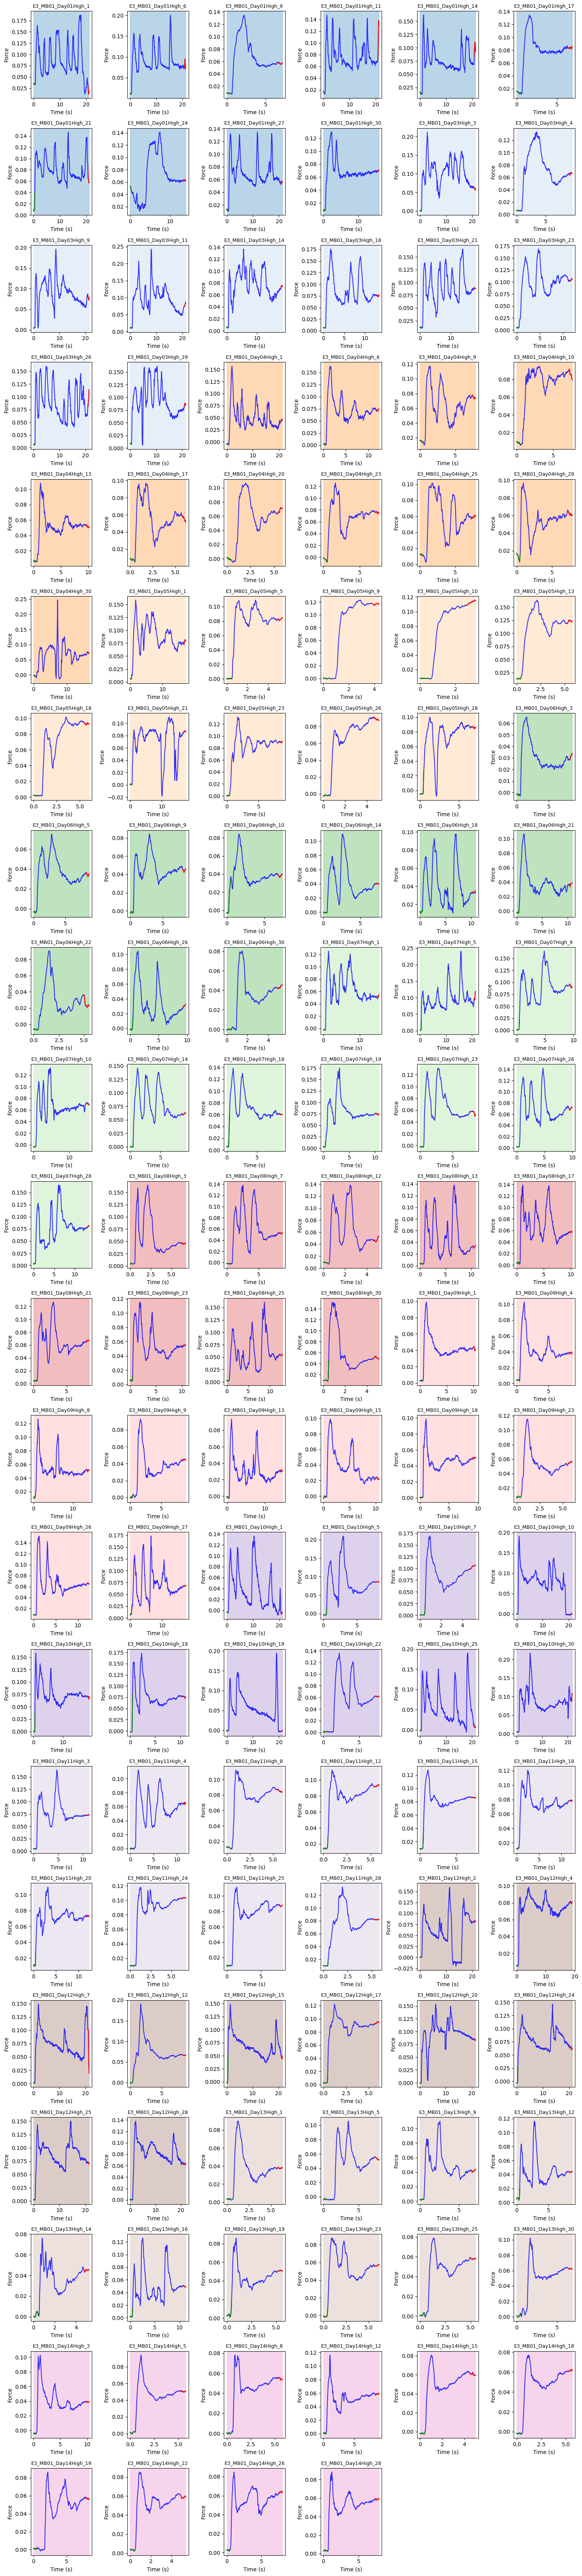


✓ Force trajectories plotted
  Green: Start of trial
  Red: End of trial
  Background color: Session day


In [9]:
from utils.functions_analysis_online_control_exp.force_trajectories import create_force_plots_by_day

# Plot force for all trials, color-coded by day
directory_path = os.path.join(base_data_dir, 'S1')
fsamp = 2048
highlight_samples = 1000  # Samples to highlight at start/end

print("Creating force trajectory plots...")
fig = create_force_plots_by_day(directory_path, fsamp, highlight_samples, extract_day, extract_trial)
plt.show()

print("\n✓ Force trajectories plotted")
print("  Green: Start of trial")
print("  Red: End of trial")
print("  Background color: Session day")

### 3.3 Force trajectories: First 2 vs Last 2 days (block layout)

Plotting force block comparison (Day1-2 vs Day13-14)...


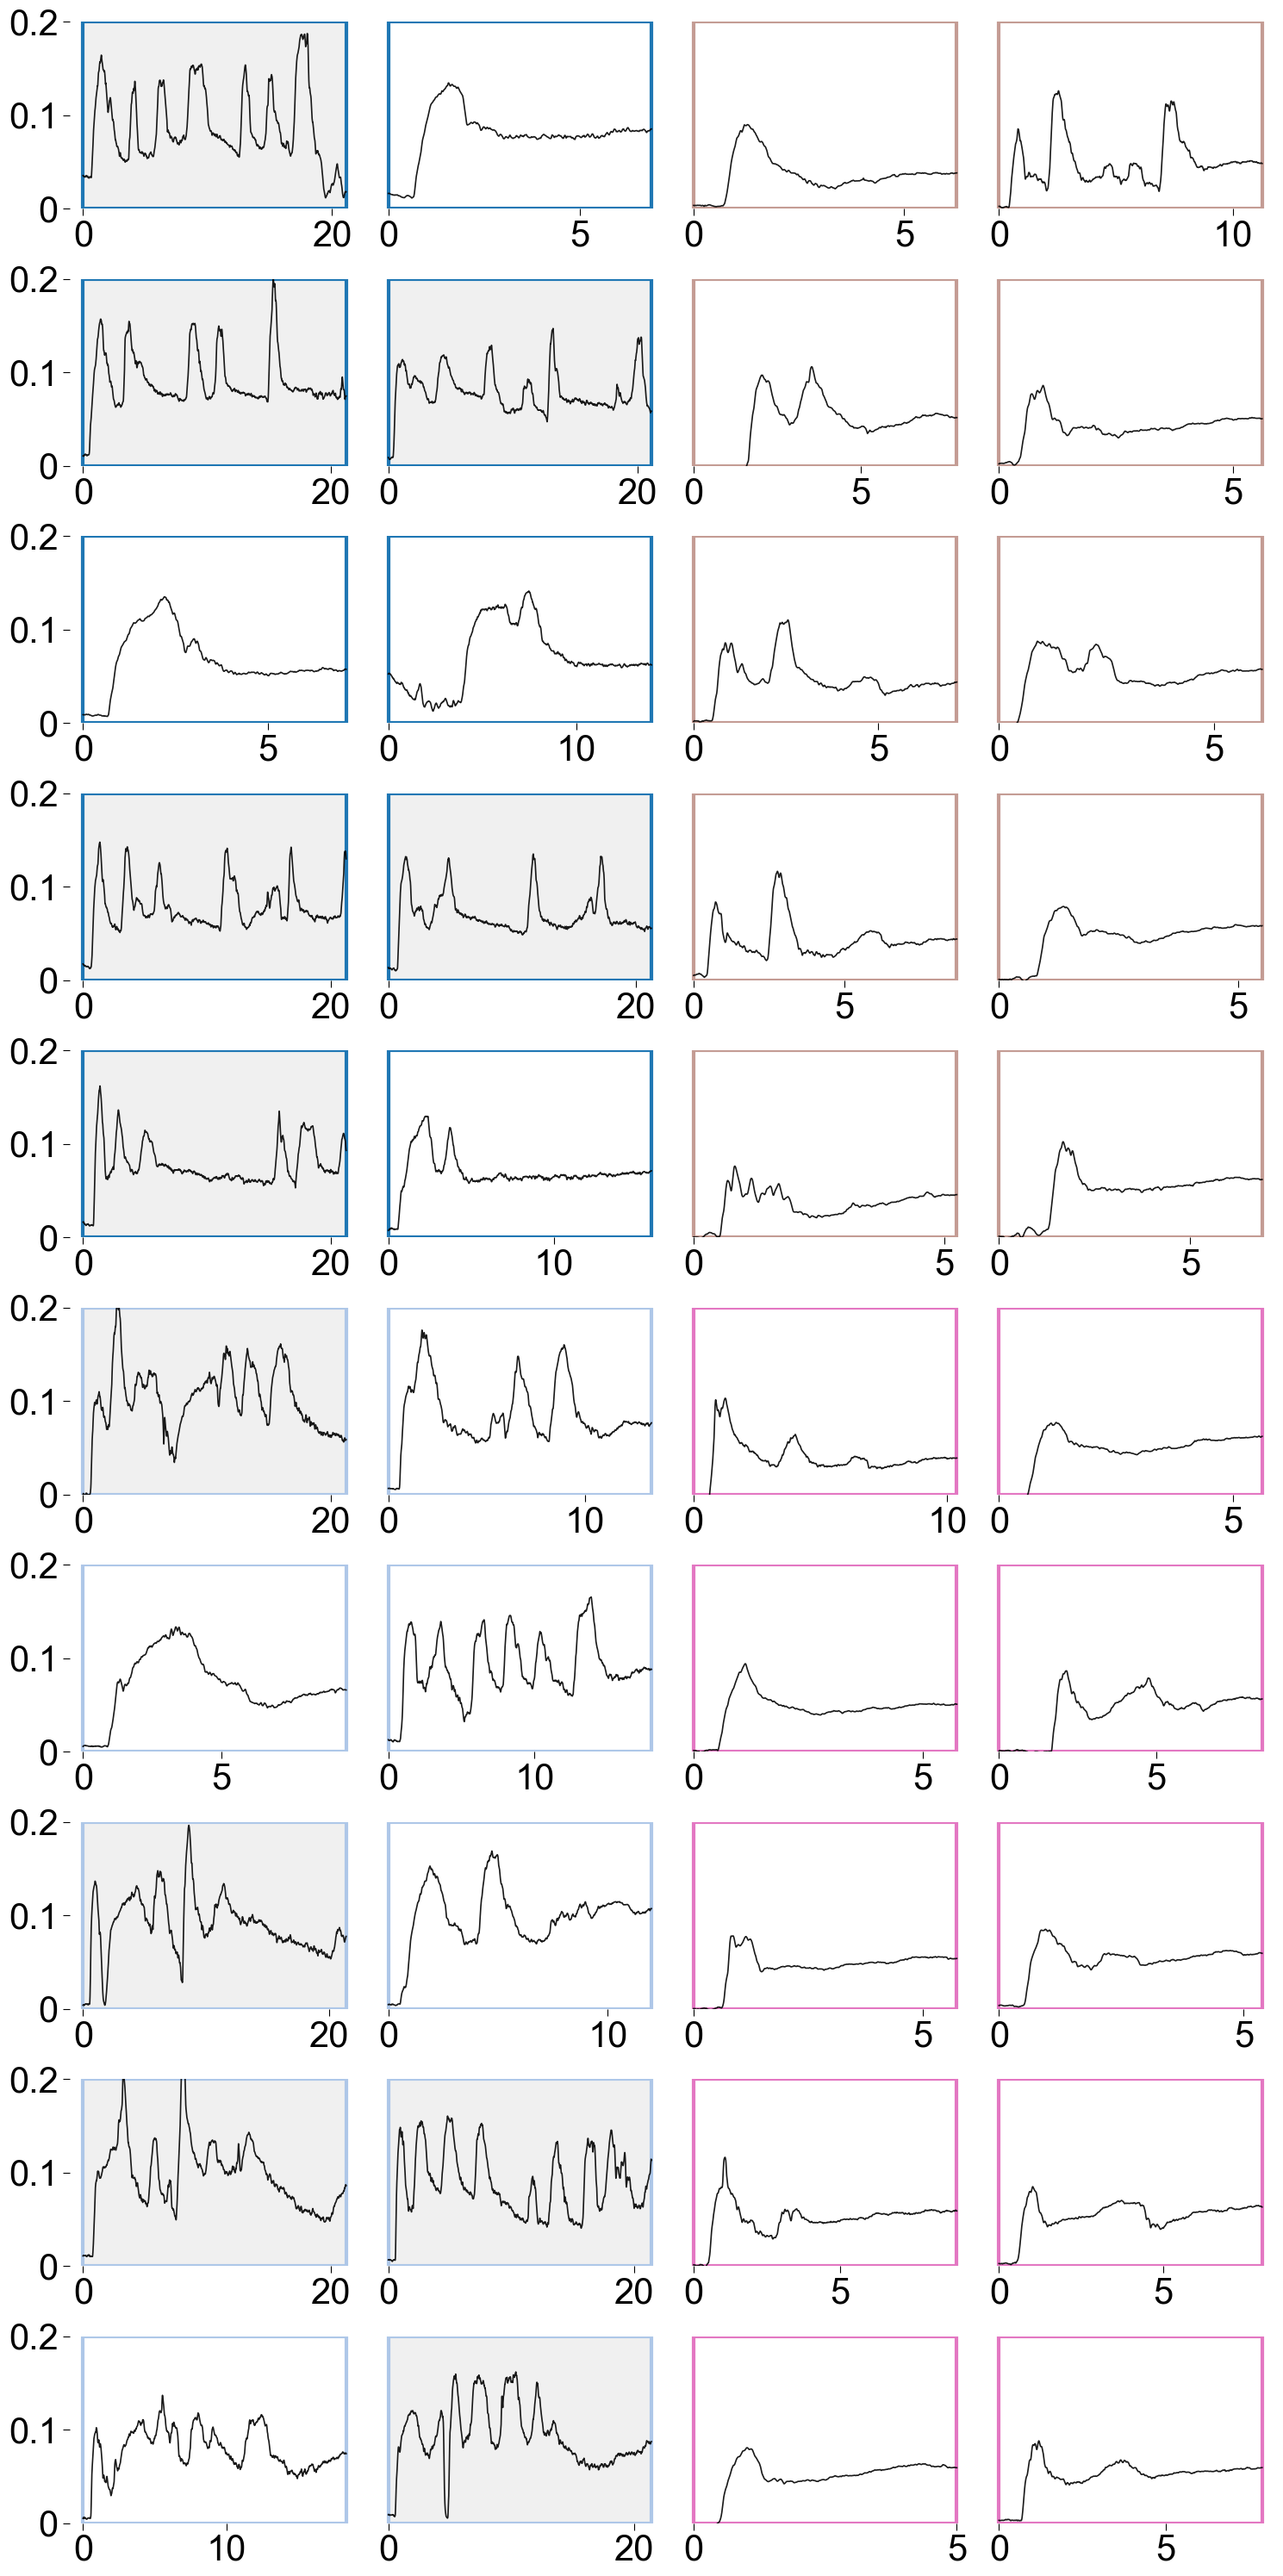


✓ Block layout force comparison plotted
  Left: Day 1-2 (early training)
  Right: Day 13-14 (late training)
  Gray fill: Trials >19 seconds (unsuccessful)


In [10]:
from utils.functions_analysis_online_control_exp.force_trajectories import plot_force_trials_block

# Compare early vs late learning with 2×2 block layout
directory_path = os.path.join(base_data_dir, 'S1')

print("Plotting force block comparison (Day1-2 vs Day13-14)...")
plot_force_trials_block(directory_path=directory_path,
    fsamp=2048,
    highlight_seconds=0,
    long_trial_thresh_s=19.0,  # Trials >19s marked as "not good"
    y_max=0.2,
    save_path=None  # Set path to save figure
)

print("\n✓ Block layout force comparison plotted")
print("  Left: Day 1-2 (early training)")
print("  Right: Day 13-14 (late training)")
print("  Gray fill: Trials >19 seconds (unsuccessful)")

### 3.4 Measure force signal smoothness

Computing force smoothness metrics...


/Users/nmt121/Desktop/Repositories/Motoneuron_Model/utils/functions_analysis_online_control_exp/smoothness_force_signal.py:121: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(data=df, x="Group", y="Smoothness", hue="Day",dodge=True, jitter=0.25, alpha=0.5, size=8,ax=ax, palette="tab10", edgecolor='gray', linewidth=0.2)
/Users/nmt121/Desktop/Repositories/Motoneuron_Model/utils/functions_analysis_online_control_exp/smoothness_force_signal.py:136: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(["First sessions", "Last sessions"], fontsize=16)
/var/folders/xt/z8_l6n9d1wv6vpcb5vdsp1dr0000gq/T/ipykernel_80989/3022005462.py:147: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(data=df, x="Group", y="Smoothness", h

Mann-Whitney U Test
U = 314.000
p-value = 0.002139
n (early) = 20, n (late) = 20
Rank-biserial correlation = -0.570
Median early = 0.0624
Median late = 0.0497


/var/folders/xt/z8_l6n9d1wv6vpcb5vdsp1dr0000gq/T/ipykernel_80989/3022005462.py:158: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(["First sessions", "Last sessions"], fontsize=16)
/Users/nmt121/Desktop/Repositories/Motoneuron_Model/.conda/lib/python3.12/site-packages/statsmodels/regression/mixed_linear_model.py:2237: ConvergenceWarning: The MLE may be on the boundary of the parameter space.
  warnings.warn(msg, ConvergenceWarning)
/var/folders/xt/z8_l6n9d1wv6vpcb5vdsp1dr0000gq/T/ipykernel_80989/3022005462.py:214: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(data=df, x="Group", y="Smoothness", hue="Day", dodge=True,


Linear Mixed Model (Day as random intercept)
              Mixed Linear Model Regression Results
Model:               MixedLM    Dependent Variable:    Smoothness
No. Observations:    40         Method:                REML      
No. Groups:          4          Scale:                 0.0002    
Min. group size:     10         Log-Likelihood:        101.2966  
Max. group size:     10         Converged:             Yes       
Mean group size:     10.0                                        
-----------------------------------------------------------------
                       Coef.  Std.Err.   z    P>|z| [0.025 0.975]
-----------------------------------------------------------------
Intercept               0.061    0.007  8.479 0.000  0.047  0.074
Group[T.Last sessions] -0.014    0.010 -1.358 0.174 -0.033  0.006
Group Var               0.000    0.007                           


--------------------------------------------------
Effect (Late - Early): -0.0137
95% CI: [-0.0335, 0.0061]
p

/var/folders/xt/z8_l6n9d1wv6vpcb5vdsp1dr0000gq/T/ipykernel_80989/3022005462.py:225: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(["First sessions", "Last sessions"], fontsize=16)


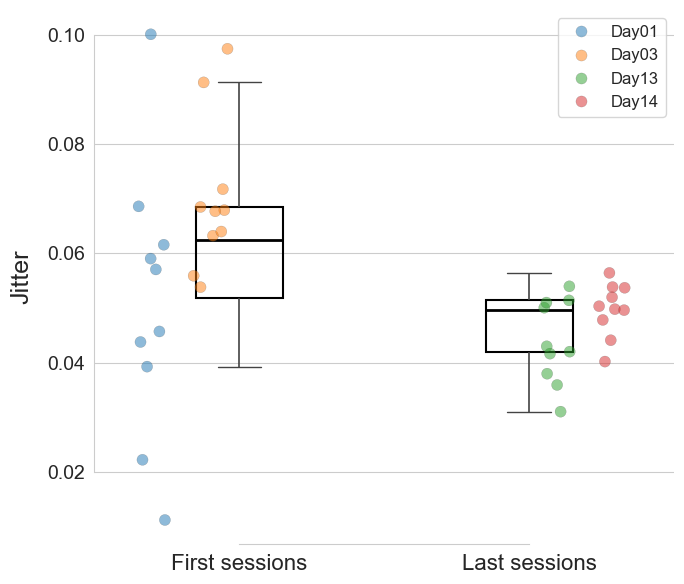

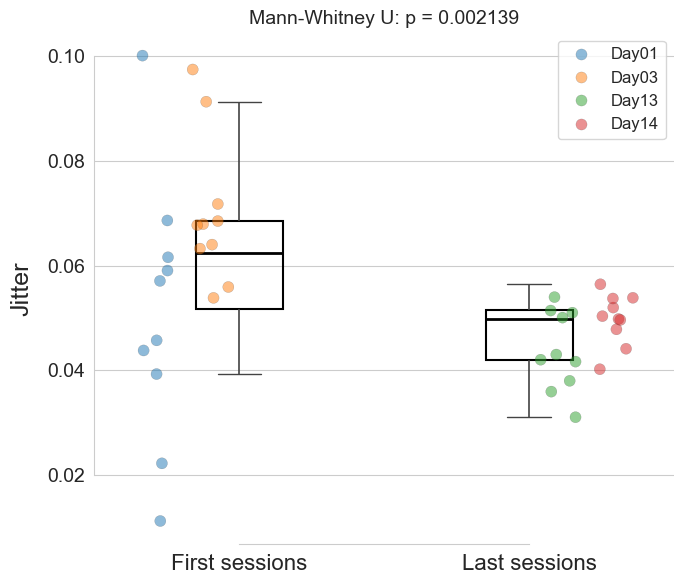

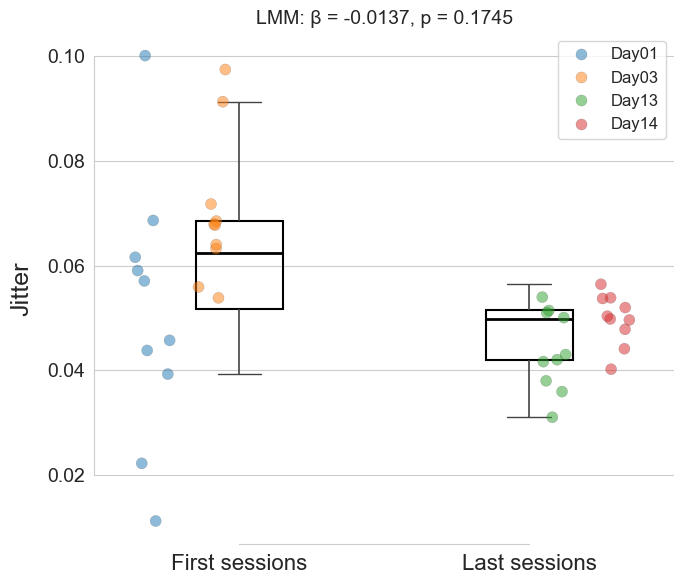


✓ Smoothness analysis complete
  Higher values = more high-frequency noise (less smooth)
  Boxplot shows Q1-Q3 range with median
  Dots show individual trials colored by session day


In [55]:
from utils.functions_analysis_online_control_exp.smoothness_force_signal import compute_signal_smoothness

# Compute smoothness (high-frequency content) for first 2 vs last 2 days
directory_path = os.path.join(base_data_dir, 'S1')

print("Computing force smoothness metrics...")
fig = compute_signal_smoothness(directory_path, fsamp=2048)


# Option 2: Mann-Whitney U test
fig, U, p, r = compute_signal_smoothness_mannwhitney(directory_path, fsamp)

# Option 3: Linear Mixed Model (recommended)
fig, model, effect, p = compute_signal_smoothness_lmm(directory_path, fsamp)



plt.show()

print("\n✓ Smoothness analysis complete")
print("  Higher values = more high-frequency noise (less smooth)")
print("  Boxplot shows Q1-Q3 range with median")
print("  Dots show individual trials colored by session day")

### 3.5 Trial success rate

In [19]:
from utils.functions_analysis_online_control_exp.success_rate import trial_success_rate_per_day

# Compute success rate (trials <19 seconds) per day
directory_path = os.path.join(base_data_dir, 'S1')

print("Computing trial success rates per day...\n")
results = trial_success_rate_per_day(directory_path, fsamp=2048, success_thresh=19.0)

print("Day    | Success Rate | Successful Trials")
print("-" * 45)
for day, stats in results.items():
    print(f"{day}  | {stats['success_rate']:6.1f}%      | {stats['n_success']}/{stats['n_total']}")

print("\n✓ Success rate computed for all days")

Computing trial success rates per day...

Day    | Success Rate | Successful Trials
---------------------------------------------
Day01  |   40.0%      | 4/10
Day03  |   50.0%      | 5/10
Day04  |   90.9%      | 10/11
Day05  |  100.0%      | 10/10
Day06  |  100.0%      | 10/10
Day07  |   90.0%      | 9/10
Day08  |  100.0%      | 9/9
Day09  |  100.0%      | 10/10
Day10  |   50.0%      | 5/10
Day11  |  100.0%      | 10/10
Day12  |   20.0%      | 2/10
Day13  |  100.0%      | 10/10
Day14  |  100.0%      | 10/10

✓ Success rate computed for all days


### 3.6 Find representative trial per day

Finding representative trials per day...



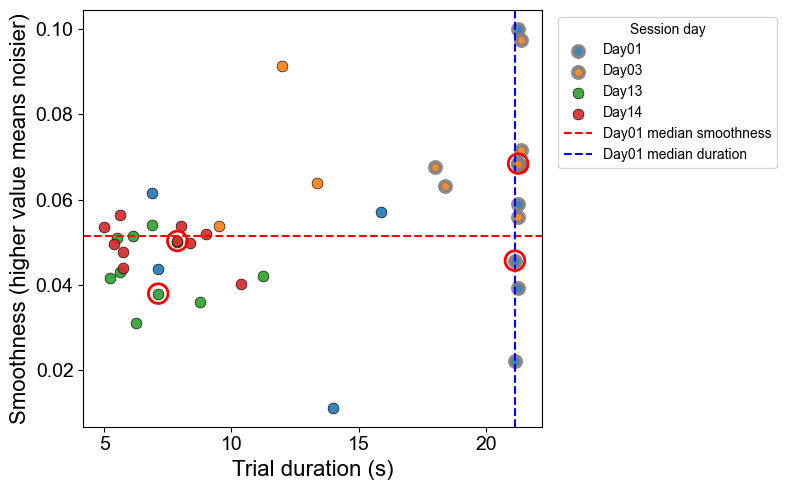

       Day  Trial                      File  TrialDur_s  Smoothness
6    Day01     21  E3_MB01_Day01High_21.pkl      21.125    0.045720
13   Day03     11  E3_MB01_Day03High_11.pkl      21.250    0.068481
22   Day04      9   E3_MB01_Day04High_9.pkl       7.875    0.051828
36   Day05     18  E3_MB01_Day05High_18.pkl       6.000    0.080721
42   Day06      5   E3_MB01_Day06High_5.pkl       8.750    0.034478
57   Day07     19  E3_MB01_Day07High_19.pkl      10.750    0.063988
67   Day08     23  E3_MB01_Day08High_23.pkl      10.750    0.044008
73   Day09      9   E3_MB01_Day09High_9.pkl       8.875    0.040275
84   Day10     15  E3_MB01_Day10High_15.pkl      18.875    0.059173
92   Day11      8   E3_MB01_Day11High_8.pkl       6.000    0.062577
108  Day12     25  E3_MB01_Day12High_25.pkl      21.375    0.062187
112  Day13      9   E3_MB01_Day13High_9.pkl       7.125    0.037995
129  Day14     28  E3_MB01_Day14High_28.pkl       7.875    0.050339

✓ Representative trials selected
  Criterion: C

In [24]:
from utils.functions_analysis_online_control_exp.choose_representative_force_trial import (
    duration_vs_smoothness_scatter_with_median
)

# Select one representative trial per day based on duration and smoothness
directory_path = os.path.join(base_data_dir, 'S1')

print("Finding representative trials per day...\n")
df_all, selected_trials = duration_vs_smoothness_scatter_with_median(
    directory_path=directory_path,
    fsamp=2048,
    high_freq_threshold=5.0,
    keep_first_last=True,  # Show only first 2 and last 2 days
    save_path=None
)

print("\n✓ Representative trials selected")
print("  Criterion: Closest to (median duration, median smoothness) in normalized space")
print("  Red circles highlight selected trials")
print("\nSelected trials per day:")
print(selected_trials)

### 3.7 Frequency content analysis (FFT)

In [28]:
# from utils.functions_analysis_online_control_exp.FFT_function import plot_fft_and_compute_metric_per_trial

# # Compute power spectral density for all trials
# directory = os.path.join(base_data_dir, 'S1')

# print("Computing FFT and power spectral density...\n")
# results = plot_fft_and_compute_metric_per_trial(
#     directory=directory,
#     fsamp=2048,
#     fmin=5.0,  # Frequency threshold for "high-frequency" power
#     max_freq=30  # Maximum frequency to display
# )

# print("\n✓ FFT analysis complete")
# print(f"  Analyzed {len(results)} trials")
# print("  Vertical line at 5 Hz marks high-frequency threshold")
print("  Separate plots per session day")

  Separate plots per session day


### 3.8 Firing rate state-space (2D trajectories)

Plotting firing rate state-space (2D trajectories)...


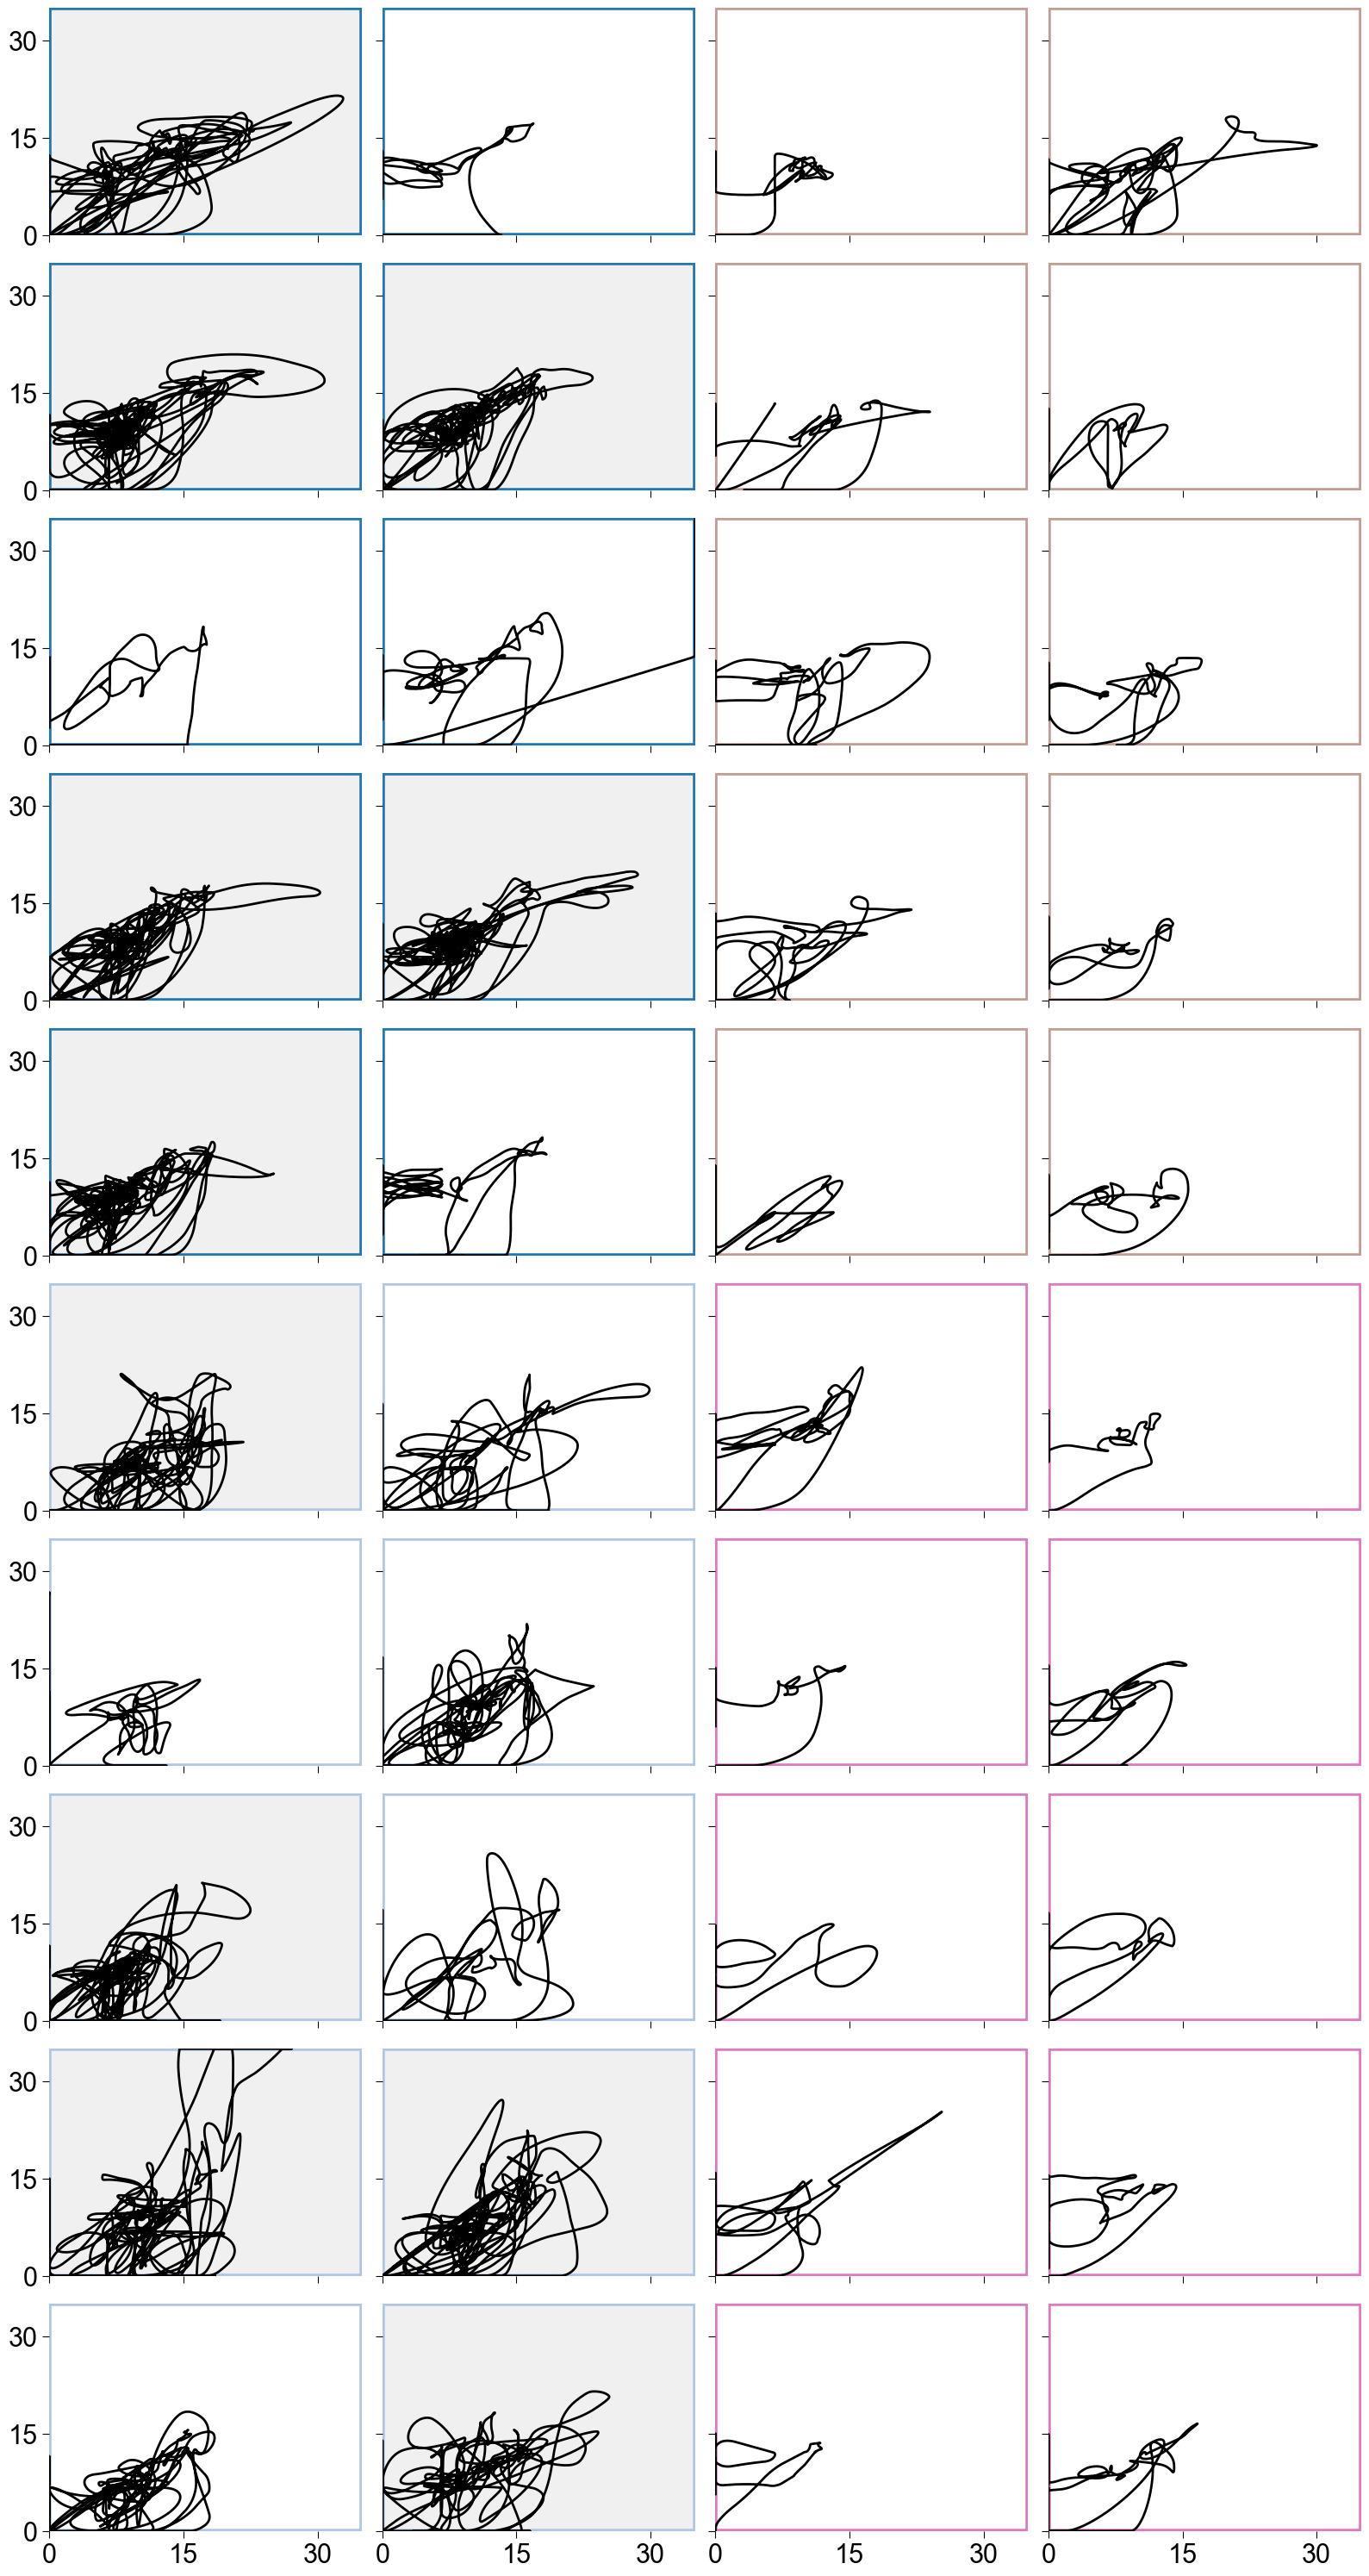


✓ 2D firing rate trajectories plotted
  x-axis: Neuron 1 firing rate (Hz)
  y-axis: Neuron 2 firing rate (Hz)
  Layout: First 2 days (left) vs Last 2 days (right)
  Gray fill: Trials >19 seconds


In [26]:
from utils.functions_analysis_online_control_exp.plot_fr_trajectories import plot_fr_trajectories_block

# Plot firing rate trajectories for MU pairs (neuron1 vs neuron2)
directory_path = os.path.join(base_data_dir, 'S1')

print("Plotting firing rate state-space (2D trajectories)...")
plot_fr_trajectories_block(
    directory_path=directory_path,
    output_path=None,
    fsamp_spikes_key='fsamp',
    force_fs=2048,
    long_trial_thresh_s=19.0,
    clip_thresh=35,  # Clip firing rates at 35 Hz
    smooth_window_s=0.30,
    xlim=(0, 35),
    ylim=(0, 35)
)

print("\n✓ 2D firing rate trajectories plotted")
print("  x-axis: Neuron 1 firing rate (Hz)")
print("  y-axis: Neuron 2 firing rate (Hz)")
print("  Layout: First 2 days (left) vs Last 2 days (right)")
print("  Gray fill: Trials >19 seconds")

### 3.9 Trial duration analysis

Plotting average trial durations for all subjects...


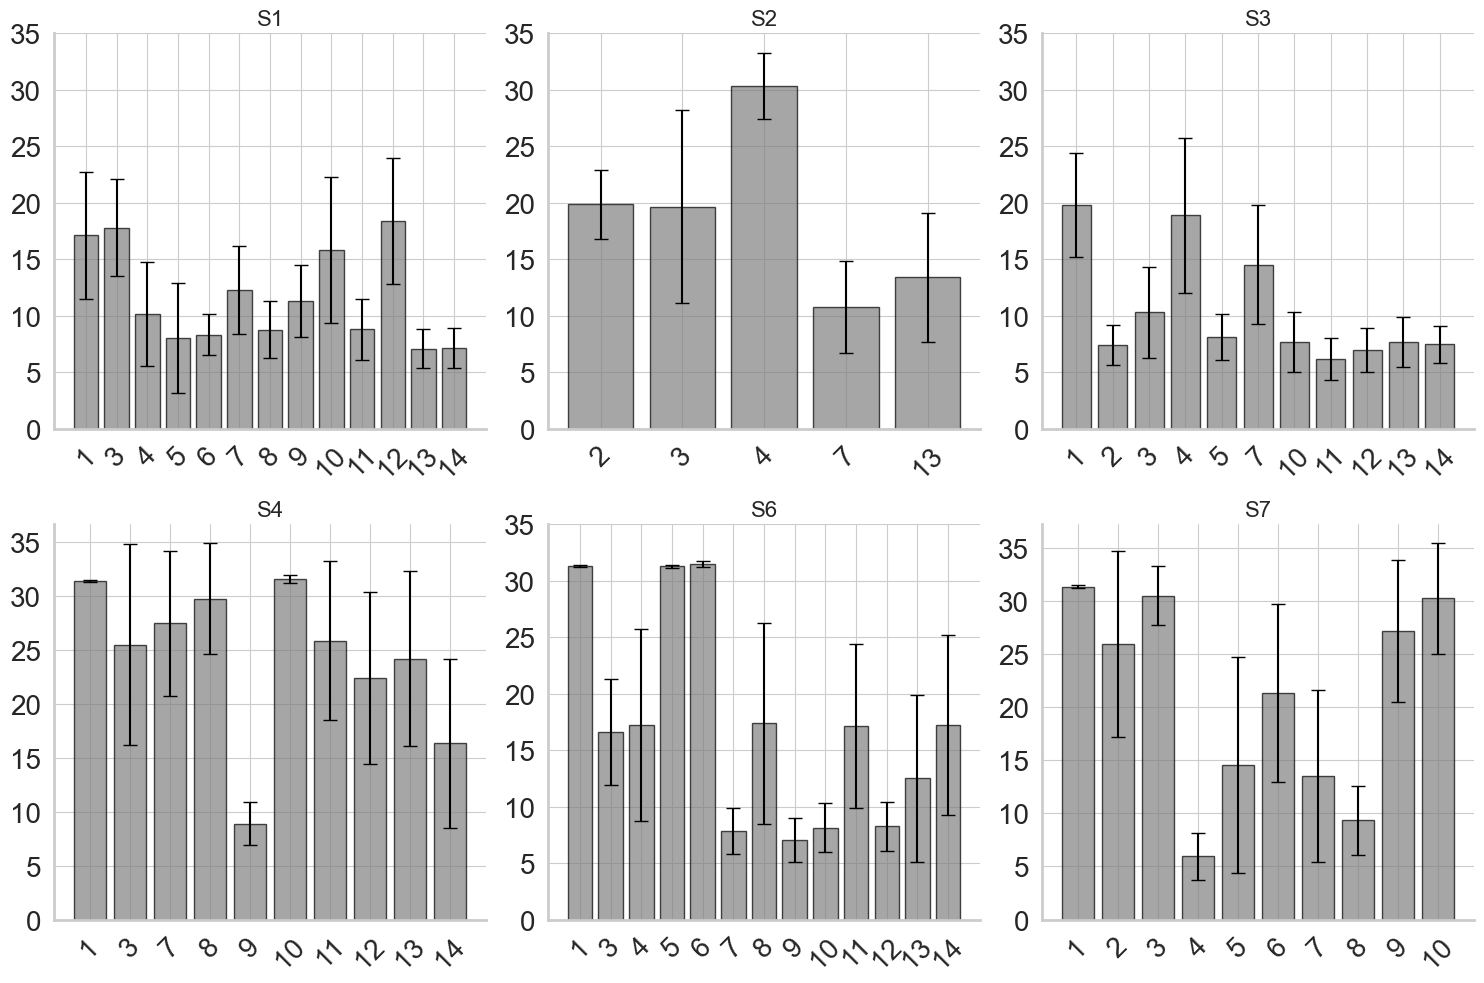


✓ Trial duration plots created for all subjects
  Bar height: Mean duration
  Error bars: Standard deviation
  2×3 layout shows all 6 subjects


In [48]:
from utils.functions_analysis_online_control_exp.trial_duration import plot_avg_trial_durations

# Plot average trial duration per day for all subjects
directory_paths = {
    'S1': os.path.join(base_data_dir, 'S1'),
    'S2': os.path.join(base_data_dir, 'S2'),
    'S3': os.path.join(base_data_dir, 'S3'),
    'S4': os.path.join(base_data_dir, 'S4'),
    'S6': os.path.join(base_data_dir, 'S6'),
    'S7': os.path.join(base_data_dir, 'S7')
}

print("Plotting average trial durations for all subjects...")
plot_avg_trial_durations(
    directory_paths=directory_paths,
    fsamp=2048,
    save_path=None
)

print("\n✓ Trial duration plots created for all subjects")
print("  Bar height: Mean duration")
print("  Error bars: Standard deviation")
print("  2×3 layout shows all 6 subjects")

### 3.10 Duration comparison: First 2 vs Last 2 days

Comparing trial durations: First 2 vs Last 2 days...


/Users/nmt121/Desktop/Repositories/Motoneuron_Model/utils/functions_analysis_online_control_exp/trial_duration.py:137: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(data=df, x="Group", y="Duration", hue="Day",
/Users/nmt121/Desktop/Repositories/Motoneuron_Model/utils/functions_analysis_online_control_exp/trial_duration.py:151: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(["First sessions", "Last sessions"], fontsize=16)


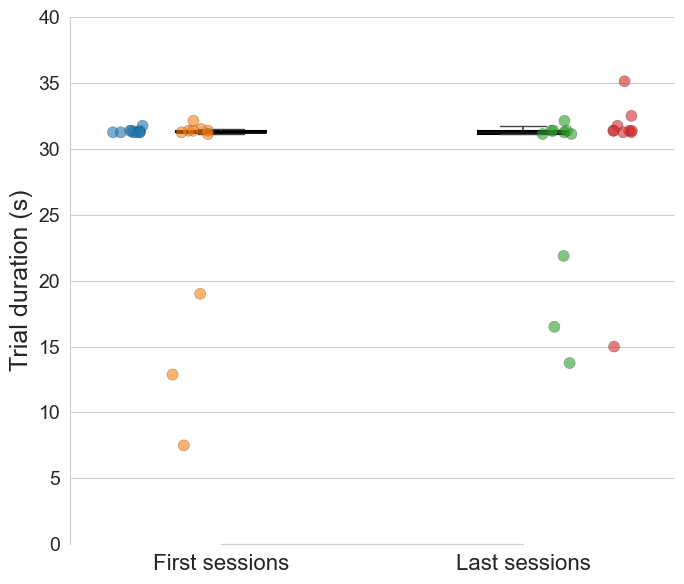


✓ Duration comparison plotted
  Boxplot shows Q1-Q3 with median
  Dots are individual trials colored by day
  Typically shows improvement (shorter durations) over training


/var/folders/xt/z8_l6n9d1wv6vpcb5vdsp1dr0000gq/T/ipykernel_80989/3959943349.py:254: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(data=df, x="Group", y="Duration", hue="Day",
/var/folders/xt/z8_l6n9d1wv6vpcb5vdsp1dr0000gq/T/ipykernel_80989/3959943349.py:268: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(["First sessions", "Last sessions"], fontsize=16)


Linear Mixed Model (Day as random intercept)
              Mixed Linear Model Regression Results
Model:                MixedLM    Dependent Variable:    Duration 
No. Observations:     40         Method:                REML     
No. Groups:           4          Scale:                 41.3941  
Min. group size:      10         Log-Likelihood:        -128.4943
Max. group size:      10         Converged:             Yes      
Mean group size:      10.0                                       
-----------------------------------------------------------------
                       Coef.  Std.Err.   z    P>|z| [0.025 0.975]
-----------------------------------------------------------------
Intercept              28.644    2.189 13.086 0.000 24.354 32.934
Group[T.Last sessions]  0.069    3.095  0.022 0.982 -5.998  6.136
Group Var               5.443    1.530                           


--------------------------------------------------
Effect (Late - Early): 0.0687 s
95% CI: [-5.9983, 6.1358]


/var/folders/xt/z8_l6n9d1wv6vpcb5vdsp1dr0000gq/T/ipykernel_80989/3959943349.py:307: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(data=df, x="Group", y="Duration", hue="Day",
/var/folders/xt/z8_l6n9d1wv6vpcb5vdsp1dr0000gq/T/ipykernel_80989/3959943349.py:321: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(["First sessions", "Last sessions"], fontsize=16)


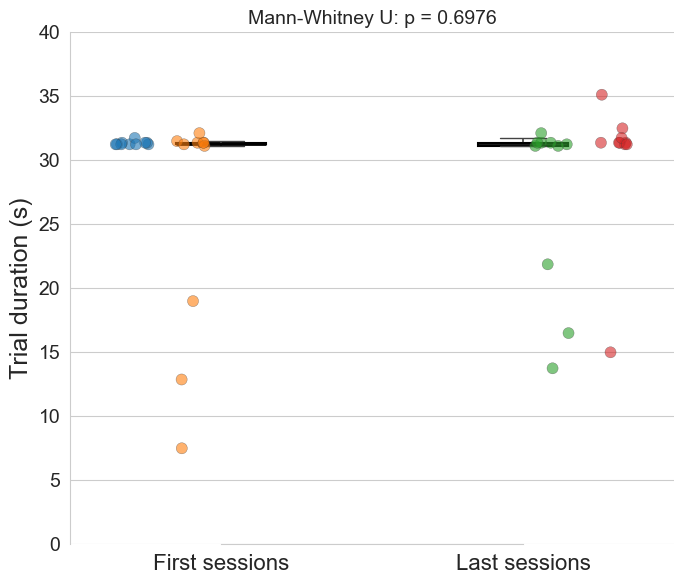

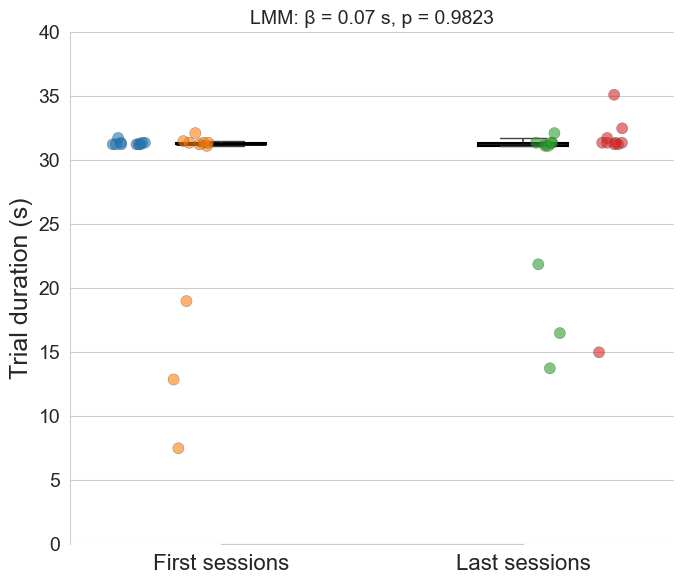

In [ ]:
from utils.functions_analysis_online_control_exp.trial_duration import plot_first_last_two_days_duration_box

# Compare trial durations between early and late training
directory_path = os.path.join(base_data_dir, 'S6')

print("Comparing trial durations: First 2 vs Last 2 days...")
fig = plot_first_last_two_days_duration_box(directory_path, fsamp=2048)
plt.show()

print("\n✓ Duration comparison plotted")
print("  Boxplot shows Q1-Q3 with median")
print("  Dots are individual trials colored by day")
print("  Typically shows improvement (shorter durations) over training")


# Mann-Whitney U test with plot
fig, stat, p = plot_duration_mannwhitney(directory_path, fsamp)

result, effect, p = run_duration_stats_lmm(directory_path, fsamp)

# LMM with plot
fig, result, effect, p = plot_duration_lmm(directory_path, fsamp)

---

## 4. Data scaling and normalization

Data scaling is required because force is used as an input signal, serving as a proxy for the common synaptic drive—in arbitrary units. Proper normalization ensures that the full motoneuron pool can be recruited and that the resulting firing patterns are comparable and physiologically realistic across sessions.

### 4.1 Scale force to target mean

Normalize all force traces so they have the same mean value for cross-session comparison.

In [ ]:
from utils.functions_analysis_online_control_exp.scale_force_with_mean import scale_and_save_all_trials_mean

# Scale all trials to have target mean = 0.3
directory_path = os.path.join(base_data_dir, 'S1')
save_dir = os.path.join(base_data_dir, 'S1_scaled_mean')

print("Scaling all force trials to target mean...\n")
scale_and_save_all_trials_mean(
    directory_path=directory_path,
    save_dir=save_dir,
    target_mean=0.3,
    plot_examples=True,
    n_examples=6,
    verbose=True
)

print("\n✓ Force scaling complete")
print(f"  Scaled .npy files saved to: {save_dir}")
print("  Manifest CSV created with scaling factors")

### 4.2 Scale representative trial per day


TWO DIFFERENT SCALING STRATEGIES:

1. REPRESENTATIVE TRIAL SCALING (Section below):
   - Selects ONE trial per day (closest to median duration/smoothness)
   - Scales all days so their GLOBAL MAX = target_max (e.g., 0.4) #0.4 being amplitude that recruits all motoneurons in the pool
   - Use case: When you need one clean exemplar trial per day
   - Output: One .npy file per day (e.g., force_Day01.npy)

2. ALL TRIALS SCALING (Section further down):
   - Scales EVERY trial individually
   - Each trial's MEAN = target_mean (e.g., 0.3)
   - Use case: When you need all trials normalized for population analysis
   - Output: One .npy file per trial (e.g., Day01_trial06.npy)



Global maximum force (before scaling): 0.2424
Scaling factor to apply: 1.6498
Saved scaled force for Day01 to /Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/Scaled_force/S1/force_S1_Day01.npy
Saved scaled force for Day03 to /Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/Scaled_force/S1/force_S1_Day03.npy
Saved scaled force for Day04 to /Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/Scaled_force/S1/force_S1_Day04.npy
Saved scaled force for Day05 to /Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/Scaled_force/S1/force_S1_Day05.npy
Saved scaled force for Day06 to /Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/Scaled_force/S1/force_S1_Day06.npy
Saved scaled force for Day07 to /Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/Scaled_force/S1/force_S1_Day07.npy
Saved scaled force for Day08 to /Users/nmt121/Desktop/Repo

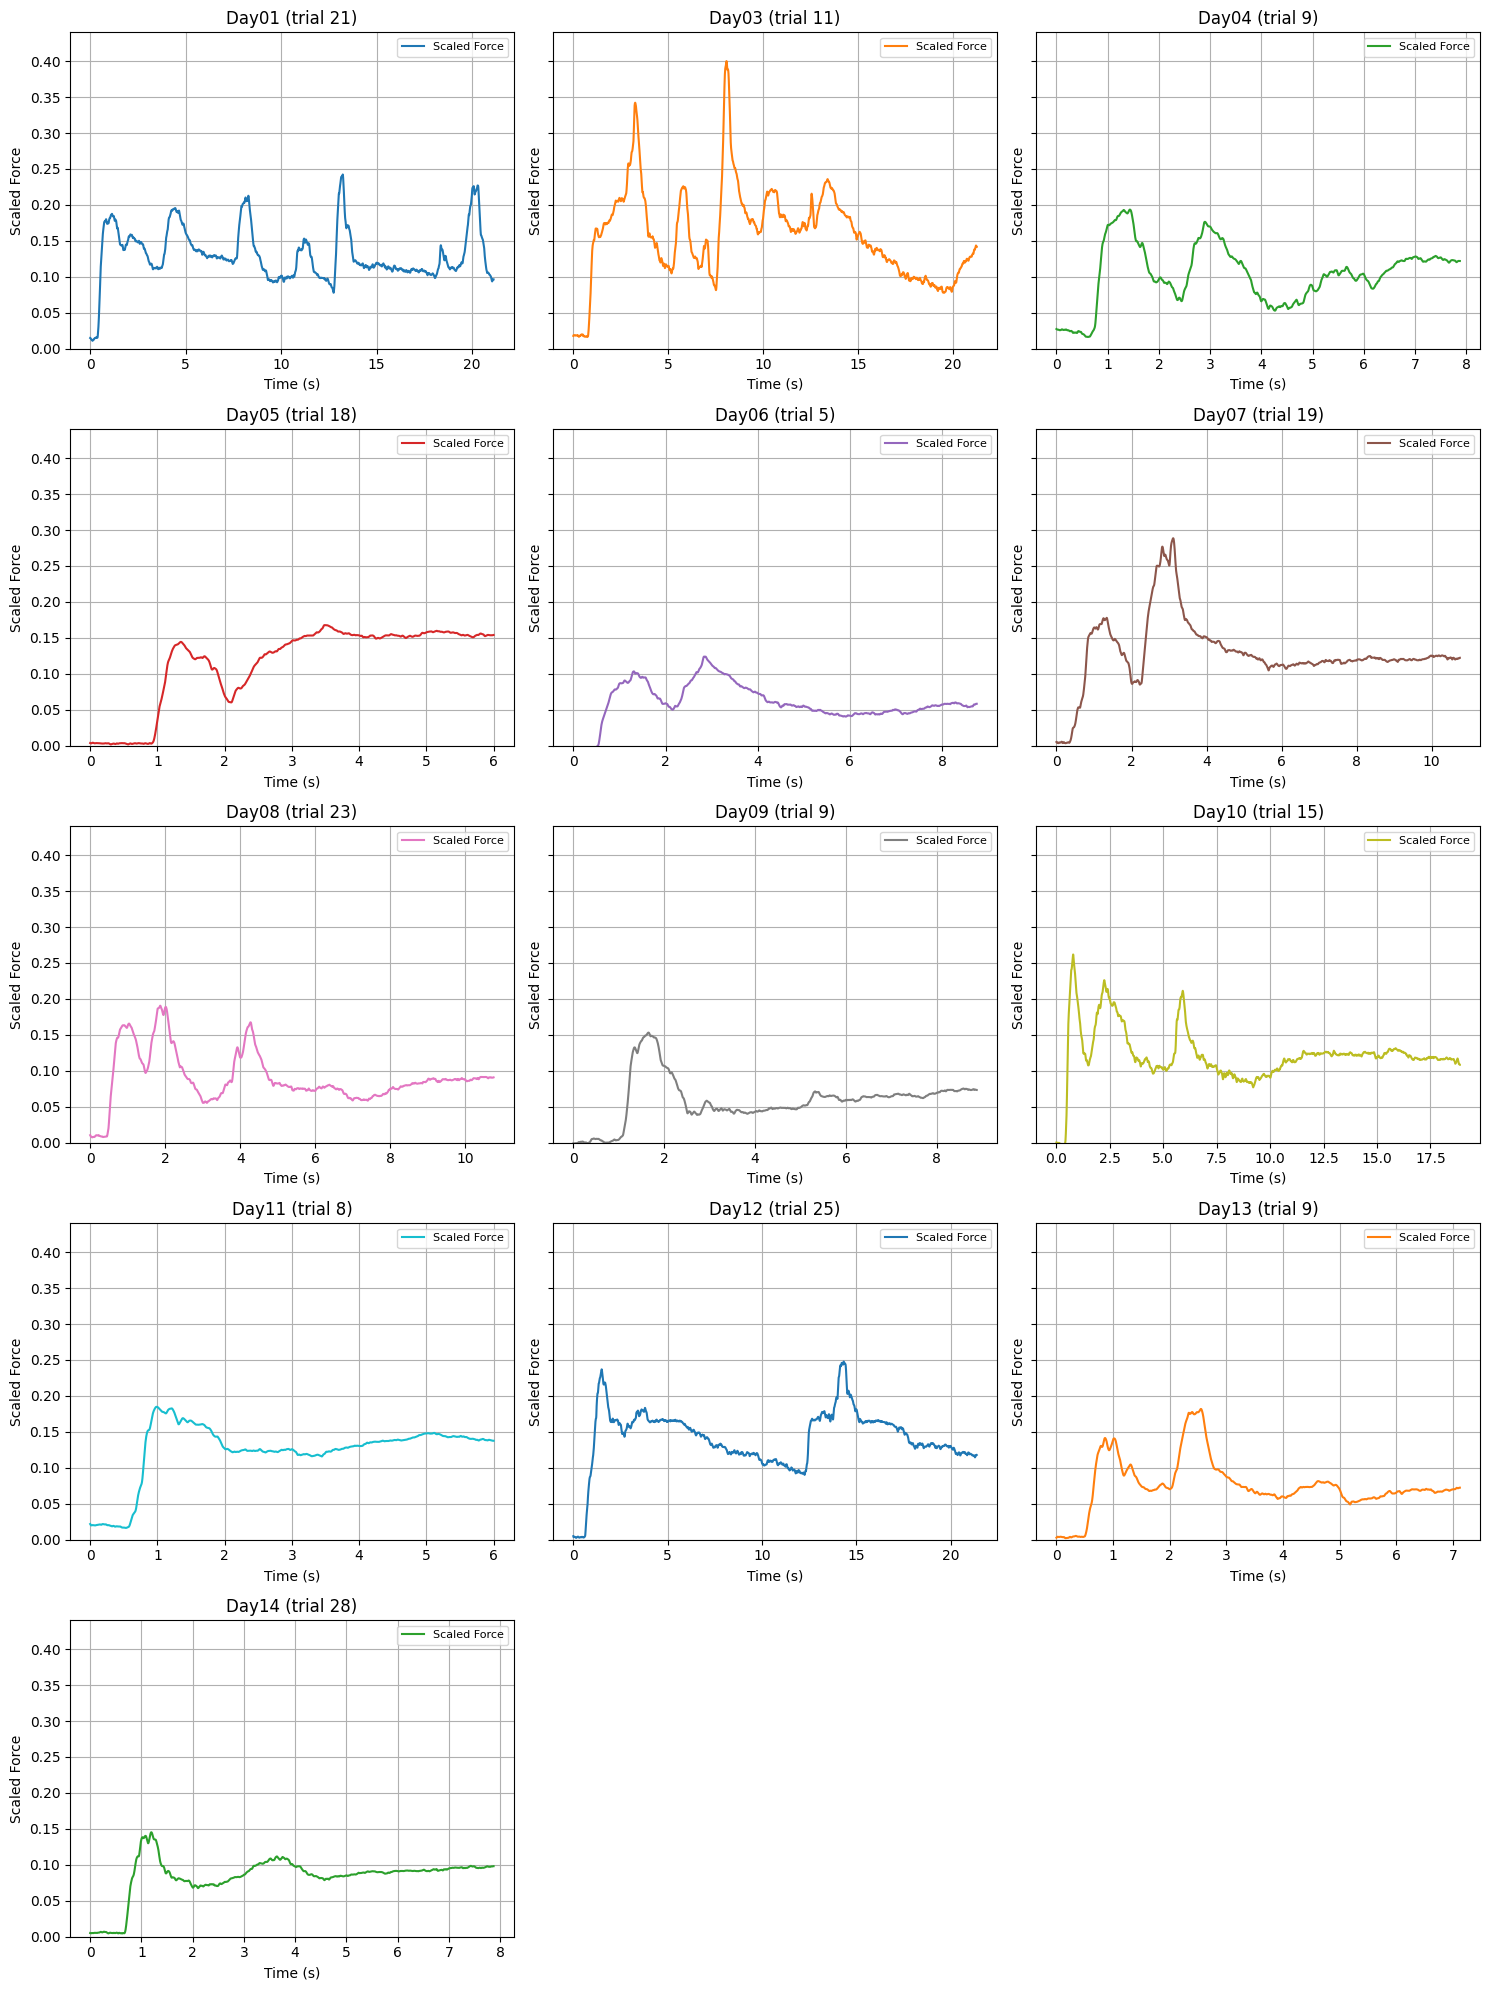


✓ Representative trials scaled and saved!
  Output: One .npy file per day
  Check the plots above to verify scaling worked correctly


In [5]:
# =============================================================================
# OPTION 1A: Scale Representative Trial Per Day
# =============================================================================
# Selects ONE trial (representative) per day and scales all days to same global max
# Use when: You want one clean exemplar per day

from utils.functions_analysis_online_control_exp.scale_force_data_with_amplitude_representativetrial import *

compute_representative_trial(
    directory_path="/Users/nmt121/Desktop/DATA/S1",
    save_dir="/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/Scaled_force/S1/",
    file_prefix="force_S1",
    target_max=0.4,  # Scale so global max across all days = 0.4
    fsamp=2048,
    plot=True,  # Shows before/after scaling
    
    # Trial numbers to use per day (from representative trial selection):
    trial_numbers_by_day=[21, 11, 9, 18, 5, 19, 23, 9, 15, 8, 25, 9, 28]
    # Order: Day01, Day03, Day04, Day05, Day06, Day07, Day08, Day09, Day10, Day11, Day12, Day13, Day14
)

print("\n✓ Representative trials scaled and saved!")
print("  Output: One .npy file per day")
print("  Check the plots above to verify scaling worked correctly")

Day01 trial 01: mean_before=0.0758 → target_mean=0.3000 scale=3.957165 (mean_after=0.3000)  -> Day01_trial01.npy
Day01 trial 06: mean_before=0.0801 → target_mean=0.3000 scale=3.744254 (mean_after=0.3000)  -> Day01_trial06.npy
Day01 trial 09: mean_before=0.0592 → target_mean=0.3000 scale=5.067241 (mean_after=0.3000)  -> Day01_trial09.npy
Day01 trial 11: mean_before=0.0650 → target_mean=0.3000 scale=4.616757 (mean_after=0.3000)  -> Day01_trial11.npy
Day01 trial 14: mean_before=0.0646 → target_mean=0.3000 scale=4.641456 (mean_after=0.3000)  -> Day01_trial14.npy
Day01 trial 17: mean_before=0.0674 → target_mean=0.3000 scale=4.449558 (mean_after=0.3000)  -> Day01_trial17.npy
Day01 trial 21: mean_before=0.0725 → target_mean=0.3000 scale=4.137550 (mean_after=0.3000)  -> Day01_trial21.npy
Day01 trial 24: mean_before=0.0569 → target_mean=0.3000 scale=5.273955 (mean_after=0.3000)  -> Day01_trial24.npy
Day01 trial 27: mean_before=0.0592 → target_mean=0.3000 scale=5.066415 (mean_after=0.3000)  -> D

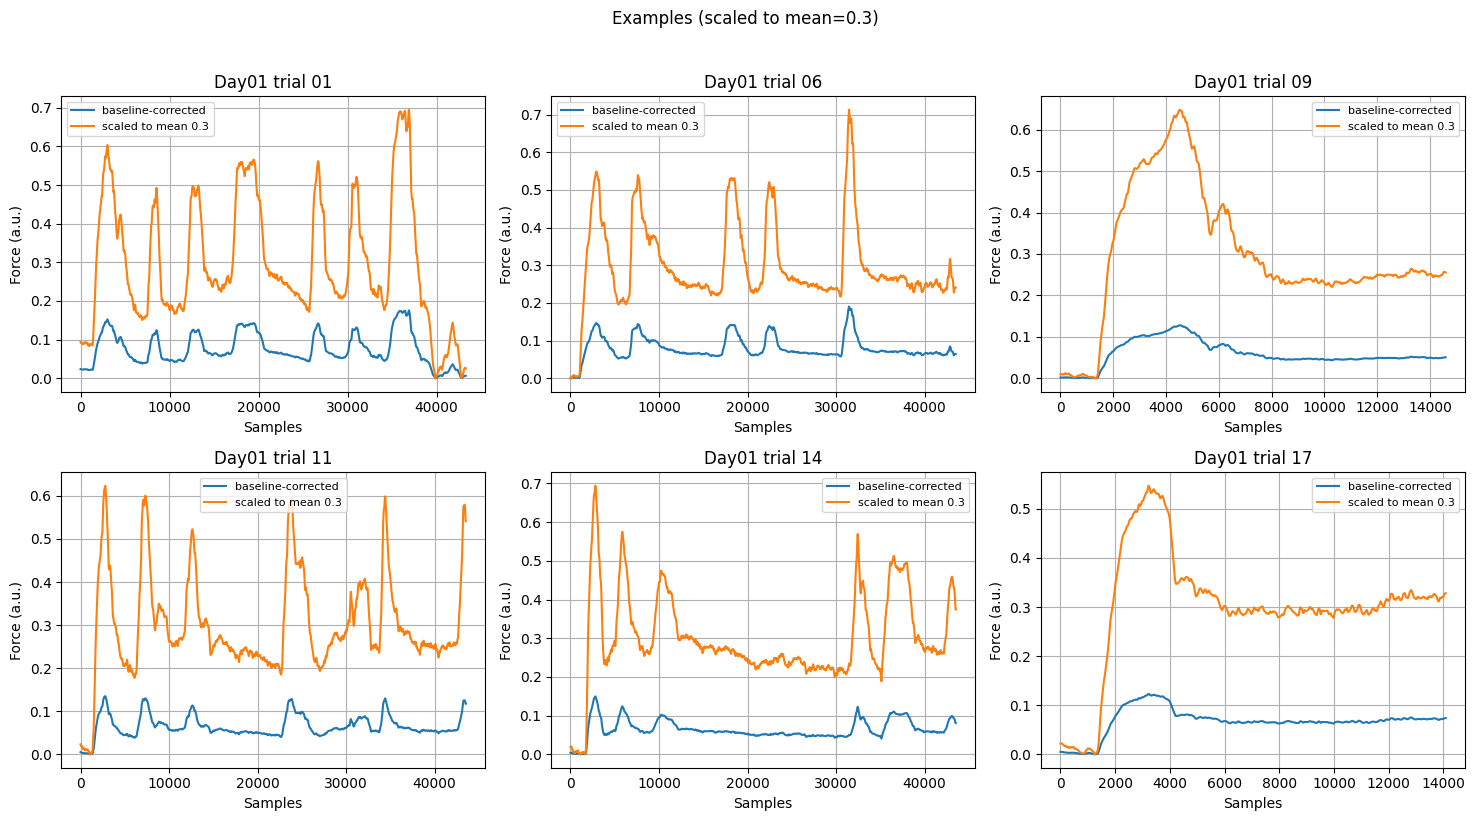


✓ All trials scaled and saved!
  Output: One .npy file per trial + manifest CSV
  Check the example plots above to verify scaling


In [6]:
# =============================================================================
# OPTION 1B: Scale All Trials to Target Mean
# =============================================================================
# Scales EVERY trial individually to same mean (FOR THE GLM)
# Use when: You need all trials normalized for population analysis

from utils.functions_analysis_online_control_exp.scale_force_with_mean import *

scale_and_save_all_trials_mean(
    directory_path="/Users/nmt121/Desktop/DATA/S1",
    save_dir="/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/Scaled_force/S1_alltrials/",
    target_mean=0.3,  # Each trial's mean will be exactly 0.3, chose so all motoneurons are recruited
    plot_examples=True,  # Shows 6 example trials before/after
    n_examples=6,
    overwrite=True,
    verbose=True,
    manifest_name="manifest_mean.csv"  # CSV with scaling factors
)

print("\n✓ All trials scaled and saved!")
print("  Output: One .npy file per trial + manifest CSV")
print("  Check the example plots above to verify scaling")

In [10]:
# =============================================================================
# FIRING RATE DISTRIBUTION COMPARISON: Experimental vs Simulated
# =============================================================================
# Import the module with correct name
from utils.functions_analysis_online_control_exp.distributions_exp_vs_simulated import *

import matplotlib.pyplot as plt

In [ ]:
# =============================================================================
# EXAMPLE 1: Trial-by-Trial Comparison (Single Day)
# =============================================================================
# Compare firing rates trial-by-trial for Day 2 of Subject 2
# Creates one subplot per trial showing experimental (blue) vs simulated (red)

exp_folder = "/Users/nmt121/Desktop/DATA/S2"
sim_folder = "/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/firings/S2/new/Day1"

print("Running trial-by-trial comparison...\n")

fig = compare_by_trial(
    exp_folder=exp_folder,
    sim_folder=sim_folder,
    target_day=2,           # Analyze Day 2 from experimental data
    fs=2048,                # Sampling frequency
    fr_cap=80.0,            # Cap firing rates at 80 Hz
    save_path=None          # Set to "/path/to/figure.pdf" to save
)

plt.show()

print("\n✓ Trial-by-trial comparison complete!")
print("  Each subplot shows one trial")
print("  Blue histogram = Experimental data")
print("  Red histogram = Simulated data")

In [ ]:
# =============================================================================
# EXAMPLE 2: Day-by-Day Comparison (Multiple Days, Aggregate)
# =============================================================================
# Compare firing rates day-by-day across entire training
# Pools all trials within each day for aggregate comparison

exp_folder = "/Users/nmt121/Desktop/DATA/S1"

# List of simulation files (one per day)
sim_files = [
    '/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/firings/S1/force1_firing_rates_last_trial.jld2',
    '/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/firings/S1/force3_firing_rates.jld2',
    '/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/firings/S1/force4_firing_rates.jld2',
    '/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/firings/S1/force5_firing_rates.jld2',
    '/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/firings/S1/force6_firing_rates.jld2',
    '/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/firings/S1/force7_firing_rates.jld2',
    '/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/firings/S1/force8_firing_rates.jld2',
    '/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/firings/S1/force9_firing_rates.jld2',
    '/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/firings/S1/force10_firing_rates.jld2',
    '/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/firings/S1/force11_firing_rates.jld2',
    '/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/firings/S1/force12_firing_rates.jld2',
    '/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/firings/S1/force13_firing_rates.jld2',
    '/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/firings/S1/force14_firing_rates_last_trial.jld2',
]

print("Running day-by-day comparison...\n")

fig = compare_by_day(
    exp_folder=exp_folder,
    sim_file_paths=sim_files,
    fs=2048,
    fr_cap=80.0,
    save_path=None  # Set to "/path/to/figure.pdf" to save
)

plt.show()

print("\n✓ Day-by-day comparison complete!")
print("  Each subplot shows one training day")
print("  Blue histogram = Experimental (all trials pooled)")
print("  Red histogram = Simulated")